<div align="center">

# Olist E-Commerce Performance Analysis
### Sales · Customers · Products · Delivery · Payments · Sellers

*An end-to-end analysis of the Brazilian Olist marketplace, September 2016 – October 2018*

**Role:** Data Analyst at `Olist` (e-commerce marketplace) &nbsp;|&nbsp; **Tools:** Python · Pandas · Matplotlib · Seaborn

</div>

## Introduction

**Context.** Olist is a Brazilian online marketplace that connects small and medium-sized sellers with customers across the country. Every order touches three sides of the business: the **customers** who buy, the **sellers** who supply, and the **delivery network** that connects them. Leadership needs one trustworthy view of how the marketplace performs on each side.

**Objective.** Turn nine raw relational tables into evidence-based answers to **25 business questions across six themes**, and be explicit about what the data can and cannot support.

**Deliverables.** This notebook (cleaning, analysis, charts and written answers), a `README.md` summary with recommendations, and a PDF report in the `Report/` folder.

## About the Data

Nine anonymized tables covering orders placed between **4 September 2016 and 17 October 2018**. Orders sit at the centre and link to customers, items, payments and reviews; items link on to products and sellers; ZIP-code prefixes link customers and sellers to geolocation (see `Data/HRhd2Y0.png` for the data model).

| Table | Rows | One row per… |
|---|--:|---|
| `orders` | 99,441 | order |
| `customers` | 99,441 | customer ID **per order** (`customer_unique_id` identifies the person) |
| `order_items` | 112,650 | item within an order |
| `order_payments` | 103,886 | payment record (an order can have several) |
| `order_reviews` | 99,224 | review (an order can have more than one) |
| `products` | 32,951 | product |
| `sellers` | 3,095 | seller |
| `geolocation` | 1,000,163 | coordinate per ZIP prefix (738,332 after removing exact duplicates) |
| `product_category_name_translation` | 71 | Portuguese → English category name |

## Analytical Approach and Conventions

**Workflow:** Load → Inspect → Clean → Join → Aggregate → Visualize → Interpret.

**Definitions used throughout**

| Metric | Definition |
|---|---|
| **Delivered product sales** | Sum of item `price` on orders with status `delivered`. Freight is **excluded**. This is a sales proxy, **not** profit or accounting revenue. |
| **Delivery time** | Customer delivery timestamp minus purchase timestamp (days), for delivered orders with both dates. |
| **Late delivery** | Delivered *after* the estimated delivery date. On or before the estimate is on time. |
| **Unique customer** | Distinct `customer_unique_id` (`customer_id` is generated per order and would overstate customers). |
| **Repeat customer** | A unique customer with more than one *delivered* order in the data window. |
| **Low review** | Review score of 1 or 2 (out of 5). |

**Conventions**
- Missing values are **kept, not imputed**; each calculation states what it excludes.
- Joins use `validate=` so an unexpected duplicate key stops the run instead of silently multiplying rows.
- Review scores are averaged **per order** before comparisons, so an order with several reviews is not counted several times.
- Every result states its **unit** (orders, items, payment records, seller-order pairs or customers). Results show **associations, not causes**.

## Notebook Roadmap

| Step / Part | Theme | Goal | Questions |
|---|---|---|---|
| [**1**](#sec-1) | Setup and Data Loading | Load the nine tables and inspect their structure | [1.1](#sec-1) Libraries · 1.2 Loading · 1.3 Structure |
| [**2**](#sec-2) | Data Cleaning and Preparation | Make the data analysis-ready without inventing values | 2.1 Dates · 2.2 Missing values · 2.3 Duplicates |
| [**A**](#part-a) | Sales Performance | Understand sales volume and how performance changes over time | [A1](#a1) How many orders? · [A2](#a2) Total sales? · [A3](#a3) Month-by-month change? · [A4](#a4) Highest and lowest months? · [A5](#a5) Growing or declining? |
| [**B**](#part-b) | Customer Analytics | Understand customer behaviour and whether customers return | [B1](#b1) Unique customers? · [B2](#b2) Repeat purchases? · [B3](#b3) Who generates the most sales? · [B4](#b4) Where are they located? |
| [**C**](#part-c) | Product Performance | Identify the most and least successful categories | [C1](#c1) Highest sales? · [C2](#c2) Most orders? · [C3](#c3) Poor performers? · [C4](#c4) Relationship with reviews? |
| [**D**](#part-d) | Delivery Performance | Identify delivery problems and check whether estimated dates are met | [D1](#d1) Average delivery time? · [D2](#d2) Share of late orders? · [D3](#d3) Slowest states? · [D4](#d4) Lateness and satisfaction? |
| [**E**](#part-e) | Payment Analysis | Understand how customers pay and how installments are used | [E1](#e1) Most-used methods? · [E2](#e2) Highest total value? · [E3](#e3) Installments by method? · [E4](#e4) Card value by installments? |
| [**F**](#part-f) | Seller Performance | Evaluate the sellers using the marketplace | [F1](#f1) Top sellers? · [F2](#f2) Delivery by seller? · [F3](#f3) Seller state vs lateness? · [F4](#f4) Persistently poor reviews? |
| [**Appendix**](#appendix) | Supplementary KPIs | Extra metrics quoted in the README and PDF report | Basket, reviews, delivery distribution, concentration, payments |

> **Customer satisfaction** is a theme that runs through the analysis rather than a separate part: category reviews in [C4](#c4), delivery versus review scores in [D4](#d4) and seller review quality in [F4](#f4). Overall review statistics are in the [Appendix](#appendix).

## How to Read Each Question

Every question follows the same pattern: **question heading → code → output or chart → answer / interpretation**. Charts are also exported to the `Plots/` folder, numbered in report order (01–20).

---

<a id="sec-1"></a>
---
## 1 · Setup and Data Loading

### 1.1 Import libraries

In [208]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1.2 Load the nine datasets

In [209]:
customers_df = pd.read_csv("Data/olist_customers_dataset.csv")
geolocation_df = pd.read_csv("Data/olist_geolocation_dataset.csv")
order_items_df = pd.read_csv("Data/olist_order_items_dataset.csv")
order_payments_df = pd.read_csv("Data/olist_order_payments_dataset.csv")
order_reviews_df = pd.read_csv("Data/olist_order_reviews_dataset.csv")
orders_df = pd.read_csv("Data/olist_orders_dataset.csv")
products_df = pd.read_csv("Data/olist_products_dataset.csv")
sellers_df = pd.read_csv("Data/olist_sellers_dataset.csv")
category_translation_df = pd.read_csv("Data/product_category_name_translation.csv")

### 1.3 Inspect structure: shapes and columns

In [210]:
dataframes = {
    "customers": customers_df,
    "geolocation": geolocation_df,
    "order_items": order_items_df,
    "order_payments": order_payments_df,
    "order_reviews": order_reviews_df,
    "orders": orders_df,
    "products": products_df,
    "sellers": sellers_df,
    "category_translation": category_translation_df
}

summary = pd.DataFrame({
    name: {
        "Shape": df.shape,
        "Columns": ", ".join(df.columns)
    }
    for name, df in dataframes.items()
})

display(summary)

,customers,geolocation,order_items,order_payments,order_reviews,orders,products,sellers,category_translation
Shape,"(99441, 5)","(1000163, 5)","(112650, 7)","(103886, 5)","(99224, 7)","(99441, 8)","(32951, 9)","(3095, 4)","(71, 2)"
Columns,"customer_id, customer_unique_id, customer_zip_...","geolocation_zip_code_prefix, geolocation_lat, ...","order_id, order_item_id, product_id, seller_id...","order_id, payment_sequential, payment_type, pa...","review_id, order_id, review_score, review_comm...","order_id, customer_id, order_status, order_pur...","product_id, product_category_name, product_nam...","seller_id, seller_zip_code_prefix, seller_city...","product_category_name, product_category_name_e..."


#### Sample of the `orders` table (transposed)

In [211]:
orders_df.sample(3).T

,87401,80284,77269
order_id,9508c52fce9468c56973500f75dbad5b,220e9a646a779158c953b9bf145606ab,133b607354fbff7447ce545c8a0fa407
customer_id,b0609e4e1e28ba6d9744ab92d21c05a6,5ffd5a0bcd9c75d85e2b2969181611ce,9e1cf20c1585106f749e4e257194a11a
order_status,delivered,delivered,delivered
order_purchase_timestamp,2017-08-18 16:26:37,2017-11-09 11:50:46,2018-08-21 21:18:33
order_approved_at,2017-08-19 02:24:50,2017-11-09 12:06:51,2018-08-25 02:44:24
order_delivered_carrier_date,2017-08-23 18:52:22,2017-11-09 18:32:27,2018-08-27 13:34:00
order_delivered_customer_date,2017-08-29 12:19:30,2017-11-20 16:37:36,2018-08-29 19:48:43
order_estimated_delivery_date,2017-09-12 00:00:00,2017-12-04 00:00:00,2018-09-05 00:00:00


<a id="sec-2"></a>
---
## 2 · Data Cleaning and Preparation

*Principle: fix what is demonstrably wrong, never invent what is unknown. The original CSV files are not modified.*

### 2.1 Date handling

In [212]:
date_columns = [
    (orders_df, [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ]),
    (order_items_df, ["shipping_limit_date"]),
    (order_reviews_df, ["review_creation_date", "review_answer_timestamp"]),
]

for df, columns in date_columns:
    for column in columns:
        df[column] = pd.to_datetime(df[column], errors="raise")

### 2.2 Missing values

In [213]:
orders_df.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [214]:
missing_rows = []

for name, df in dataframes.items():
    counts = df.isna().sum()
    for column, count in counts[counts > 0].items():
        missing_rows.append({
            "dataset": name,
            "column": column,
            "missing_count": count,
            "missing_percent": round(count / len(df) * 100, 2),
        })

missing_summary = pd.DataFrame(missing_rows)

In [215]:
display(missing_summary.sort_values(["dataset", "missing_count"], ascending=[True, False]))

,dataset,column,missing_count,missing_percent
0,order_reviews,review_comment_title,87656,88.34
1,order_reviews,review_comment_message,58247,58.70
4,orders,order_delivered_customer_date,2965,2.98
3,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_approved_at,160,0.16
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
9,products,product_weight_g,2,0.01


#### Findings and decisions

- **Order reviews:** `review_comment_title` is missing in 87,656 rows (88.34%), and `review_comment_message` in 58,247 rows (58.70%). These fields are optional, so the missing values are retained.
- **Products:** 610 rows are missing `product_category_name`, `product_name_lenght`, `product_description_lenght`, and `product_photos_qty`. Two rows are missing weight and dimension fields. The matching counts suggest these fields may be missing together; the missingness-pattern check can confirm this.
- **Orders:** Missing timestamps are mostly consistent with order status (for example, canceled or not-yet-delivered orders). A few `delivered` orders are missing timestamps: 14 approval dates, 2 carrier dates, and 8 customer-delivery dates. These are retained as missing rather than imputed or dropped.

Missing values are preserved; no rows or values are removed or imputed at this stage.

### 2.3 Duplicates

In [216]:
duplicate_summary = pd.DataFrame([
    {
        "dataset": name,
        "duplicate_rows": int(df.duplicated().sum())
    }
    for name, df in dataframes.items()
])

duplicate_summary

,dataset,duplicate_rows
0,customers,0
1,geolocation,261831
2,order_items,0
3,order_payments,0
4,order_reviews,0
5,orders,0
6,products,0
7,sellers,0
8,category_translation,0


In [217]:
geo_duplicate_groups = (
    geolocation_df.value_counts()
    .rename("copies")
    .reset_index()
)

geo_duplicate_groups = geo_duplicate_groups[
    geo_duplicate_groups["copies"] > 1
].sort_values("copies", ascending=False)

display(geo_duplicate_groups.head(12))

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,copies
0,88220,-27.102099,-48.629613,itapema,SC,314
1,6414,-23.495901,-46.874687,barueri,SP,189
2,6414,-23.490618,-46.869004,barueri,SP,127
3,5145,-23.506049,-46.717377,sao paulo,SP,126
4,22620,-23.005514,-43.375964,rio de janeiro,RJ,102
5,22640,-23.004582,-43.319899,rio de janeiro,RJ,89
6,22775,-22.965906,-43.389999,rio de janeiro,RJ,89
7,6401,-23.509243,-46.886669,barueri,SP,81
8,71936,-15.841451,-48.024026,brasilia,DF,80
9,30240,-19.924167,-43.916480,belo horizonte,MG,79


In [218]:
rows_before = len(geolocation_df)

geolocation_df = geolocation_df.drop_duplicates().reset_index(drop=True)

print(f"Rows before: {rows_before:,}")
print(f"Rows after:  {len(geolocation_df):,}")
print(f"Exact duplicates removed: {rows_before - len(geolocation_df):,}")

Rows before: 1,000,163
Rows after:  738,332
Exact duplicates removed: 261,831


In [219]:
geolocation_df.duplicated().sum()

np.int64(0)

<a id="part-a"></a>
---
## Part A · Sales Performance

> **Goal:** Understand sales volume and how the company's performance changes over time.
>
> **Questions:** A1 How many orders does Olist receive? · A2 What is the total sales revenue? · A3 How do sales and orders change month by month? · A4 Which months have the highest and lowest sales? · A5 Is the business growing or declining?

<a id="a1"></a>
### A1 · How many orders does Olist receive?

In [220]:
print("The number of orders that ``Olist`` gets is : ", orders_df['order_id'].count())

The number of orders that ``Olist`` gets is :  99441


<a id="a2"></a>
### A2 · What is the total sales revenue?

*Measured as delivered product sales: item prices on delivered orders, freight excluded.*

In [221]:
order_items_df.count()

order_id               112650
order_item_id          112650
product_id             112650
seller_id              112650
shipping_limit_date    112650
price                  112650
freight_value          112650
dtype: int64

In [222]:
delivered_order_ids = orders_df.loc[
    orders_df["order_status"] == "delivered", "order_id"
]
delivered_items = order_items_df[
    order_items_df["order_id"].isin(delivered_order_ids)
]

total_sales = delivered_items["price"].sum()
print(f"Total product sales for delivered orders: R$ {total_sales:,.2f}")

Total product sales for delivered orders: R$ 13,221,498.11


<a id="a3"></a>
### A3 · How do sales and orders change month by month?

In [223]:
orders_df['order_purchase_timestamp'].min()

Timestamp('2016-09-04 21:15:19')

In [224]:
orders_df['order_purchase_timestamp'].max()

Timestamp('2018-10-17 17:30:18')

In [225]:

orders_df['order_purchase_timestamp_month'] = orders_df["order_purchase_timestamp"].dt.to_period("M")
orders_df["order_purchase_timestamp_year"] = orders_df["order_purchase_timestamp"].dt.year


In [226]:
orders_df[['order_purchase_timestamp_month']].head(3)

,order_purchase_timestamp_month
0,2017-10
1,2018-07
2,2018-08


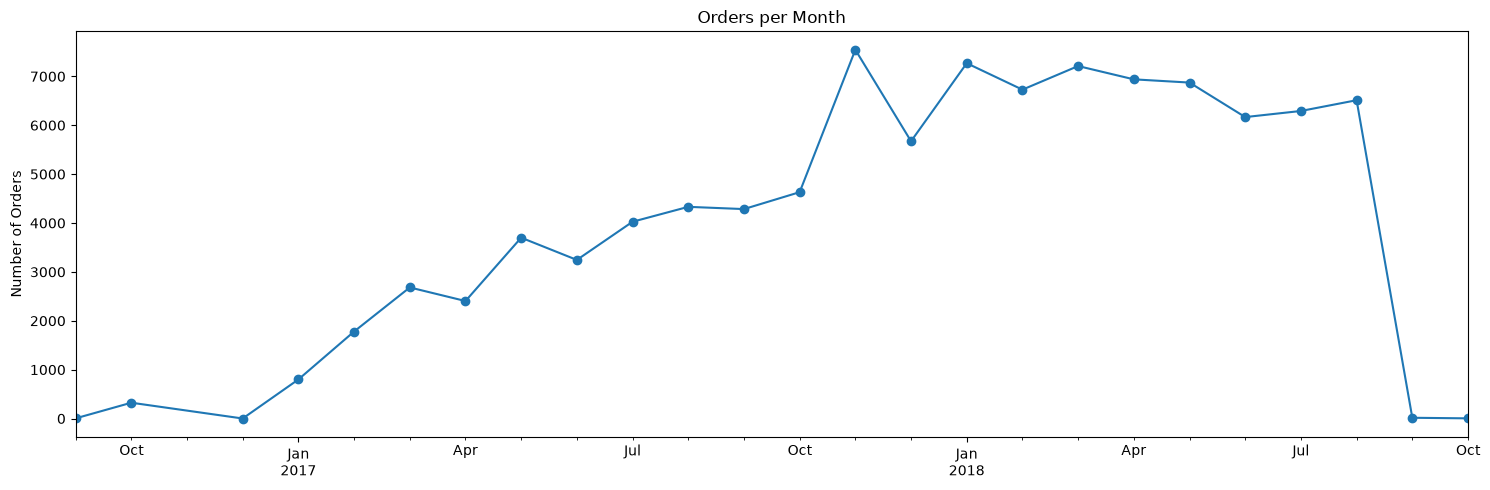

In [227]:
orders_by_month = orders_df.groupby("order_purchase_timestamp_month")["order_id"].count()

ax = orders_by_month.plot(marker="o", figsize=(15, 5))
ax.set_xlabel("")
ax.set_ylabel("Number of Orders")
ax.set_title("Orders per Month")
plt.tight_layout()
plt.show()

In [228]:
order_items_df.sample(3)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
11421,19fffb5eab0cb56530a7569759bcf889,1,e68a5a5626c4b1bfc5ca78202f898300,7a67c85e85bb2ce8582c35f2203ad736,2017-07-06 15:03:59,199.99,25.95
8435,133a94aa41cab8ad1d4cf02c2636b9cc,2,4f18ca9862f511ecba98258b2194d061,5b0cc932433fa5184b5b94bfe6bcc256,2018-08-01 09:30:11,95.00,59.90
104458,ed4f3a7d90215313e0c485f97f640584,1,a291cc846d74d97f01611894f983073b,de722cd6dad950a92b7d4f82673f8833,2018-05-29 18:31:36,189.90,14.59


In [229]:
delivered_orders = orders_df.loc[
    orders_df["order_status"] == "delivered",
    ["order_id", "order_purchase_timestamp_month"]
]

In [230]:
items_with_month = order_items_df.merge(
    delivered_orders,
    on="order_id",
    validate="many_to_one"
)

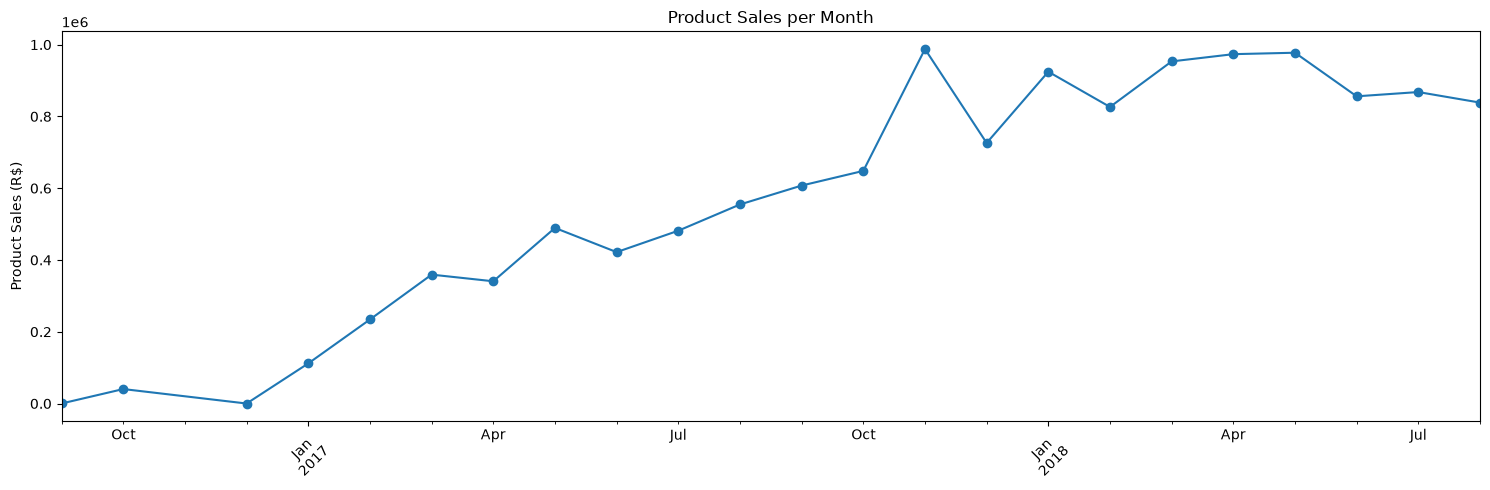

In [231]:
sales_by_month = items_with_month.groupby("order_purchase_timestamp_month")["price"].sum()

ax = sales_by_month.plot(marker="o", figsize=(15, 5))
ax.set_xlabel("")
ax.set_ylabel("Product Sales (R$)")
ax.set_title("Product Sales per Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

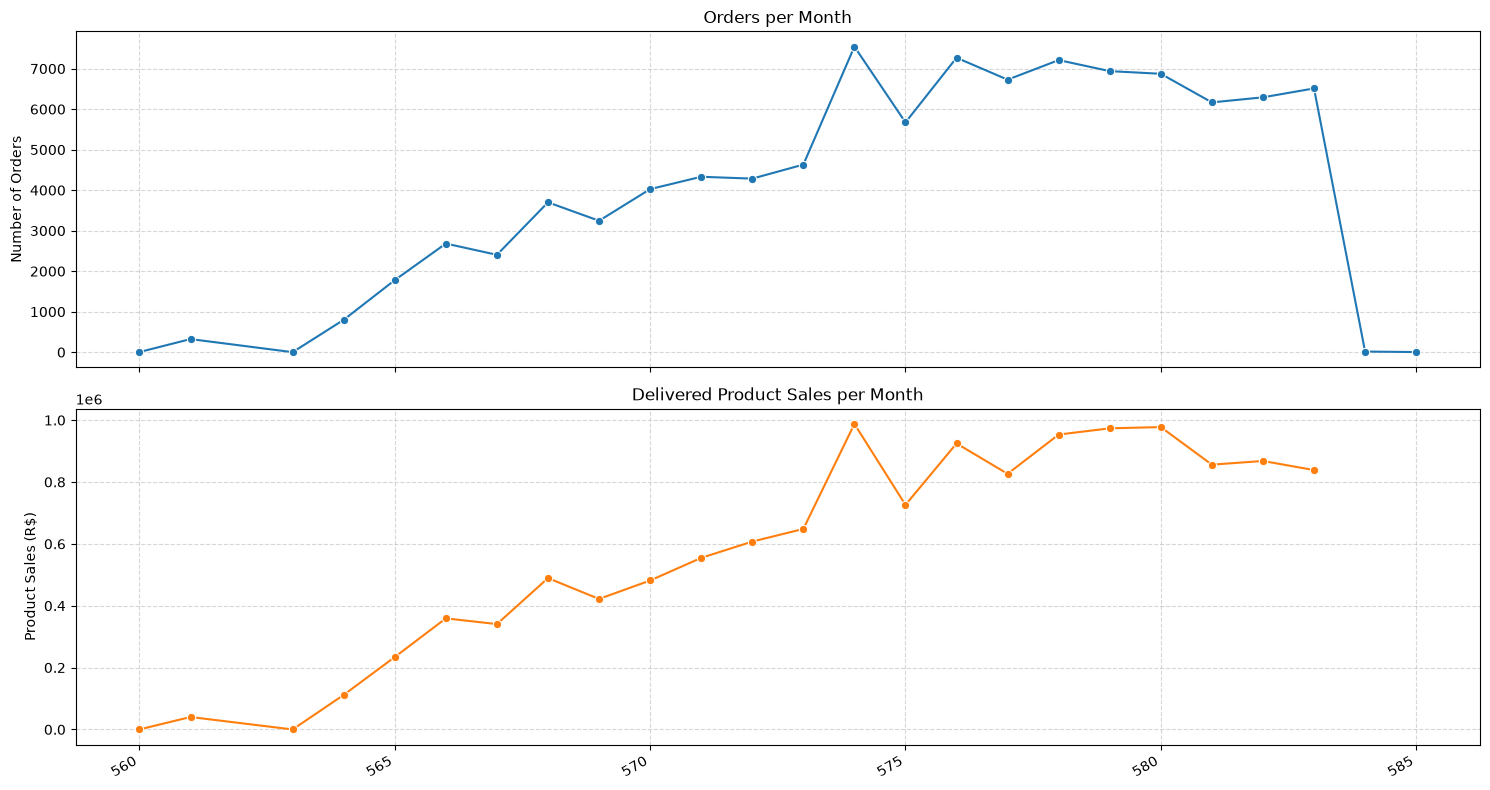

In [232]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

sns.lineplot(
    x=orders_by_month.index, y=orders_by_month.values,
    marker="o", ax=axes[0], color="tab:blue"
)
axes[0].set_title("Orders per Month")
axes[0].set_ylabel("Number of Orders")
axes[0].grid(linestyle="--", alpha=0.5)

sns.lineplot(
    x=sales_by_month.index, y=sales_by_month.values,
    marker="o", ax=axes[1], color="tab:orange"
)
axes[1].set_title("Delivered Product Sales per Month")
axes[1].set_ylabel("Product Sales (R$)")
axes[1].set_xlabel("")
axes[1].grid(linestyle="--", alpha=0.5)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

#### Answer

Monthly **orders** and **delivered product sales** generally increased from late 2016 through 2017, then fluctuated during 2018 rather than rising steadily. The apparent drop in the final months should be interpreted cautiously:``those months may be incomplete, and recent orders may not yet have been delivered``.

**Metric note:** Order count includes orders of all statuses, while sales sums item prices for delivered orders only and excludes freight.
``These measures are not directly comparable month for month.``

<a id="a4"></a>
### A4 · Which months have the highest and lowest sales?

In [233]:
print("Top 3 months:")
for month, sales in sales_by_month.nlargest(3).items():
    print(f" {month:%B %Y}: R$ {sales:,.2f}")

Top 3 months:
 November 2017: R$ 987,765.37
 May 2018: R$ 977,544.69
 April 2018: R$ 973,534.09


In [234]:
print("\nBottom 3 months with delivered sales:")
for month, sales in sales_by_month[sales_by_month > 0].nsmallest(3).items():
    print(f" {month:%B %Y}: R$ {sales:,.2f}")


Bottom 3 months with delivered sales:
 December 2016: R$ 10.90
 September 2016: R$ 134.97
 October 2016: R$ 40,325.11


In [235]:


print("\nMonths with no delivered sales recorded:")
for month in sales_by_month[sales_by_month == 0].index:
    print( month.strftime("%B %Y"))


Months with no delivered sales recorded:


<a id="a5"></a>
### A5 · Is the business growing or declining?

#### Step 1 · Unique customers per month

In [236]:
orders_with_customers = orders_df.merge(
    customers_df[["customer_id", "customer_unique_id"]],
    on="customer_id",
    validate="many_to_one"
)

orders_with_customers["order_purchase_timestamp_month"] = (
    pd.to_datetime(orders_with_customers["order_purchase_timestamp"]).dt.to_period("M").dt.to_timestamp()
)

customers_by_month = (
    orders_with_customers.groupby("order_purchase_timestamp_month")["customer_unique_id"].nunique()
)

customers_by_month.head(3).to_frame()

,customer_unique_id
order_purchase_timestamp_month,
2016-09-01,4
2016-10-01,321
2016-12-01,1


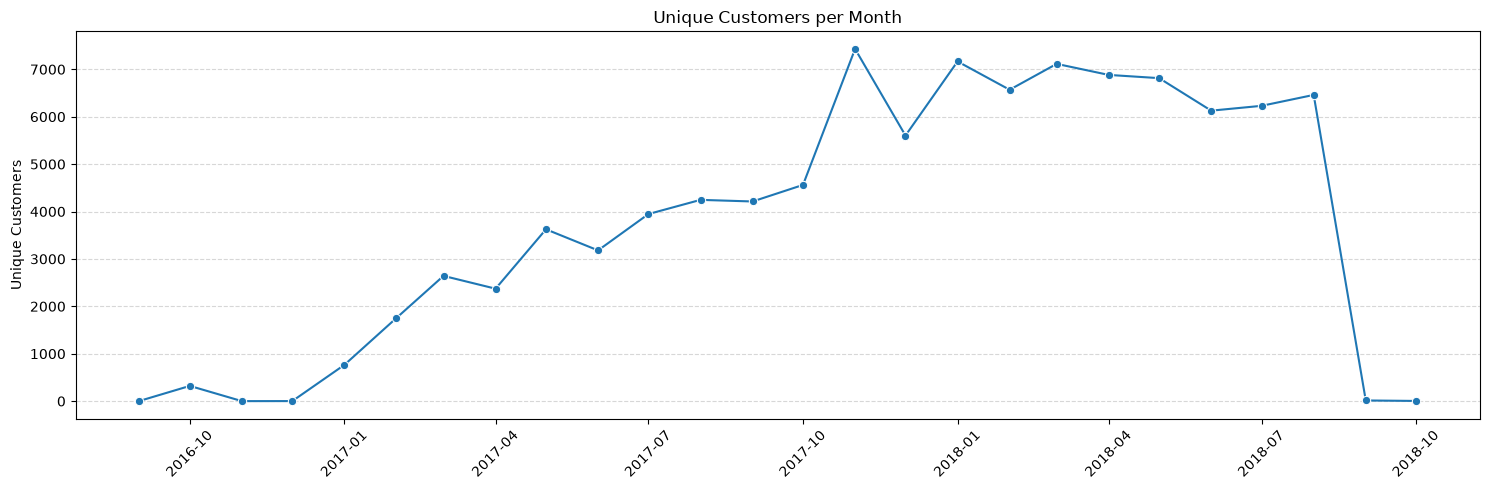

In [237]:
customers_by_month = customers_by_month.asfreq("MS", fill_value=0)

plt.figure(figsize=(15, 5))
sns.lineplot(
    x=customers_by_month.index,
    y=customers_by_month.values,
    marker="o"
)
plt.xlabel("")
plt.ylabel("Unique Customers")
plt.title("Unique Customers per Month")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

#### Step 2 · Year-over-year comparison: January–August 2017 vs January–August 2018

*The same eight months are compared so that seasonality cancels out; September–October 2018 is sparse and excluded.*

In [238]:
orders_2017 = orders_by_month.loc["2017-01":"2017-08"].sum()
orders_2018 = orders_by_month.loc["2018-01":"2018-08"].sum()

order_change_pct = (orders_2018 - orders_2017) / orders_2017 * 100

print(f"Jan–Aug 2017 orders: {orders_2017:,.0f}")
print(f"Jan–Aug 2018 orders: {orders_2018:,.0f}")
print(f"Change: {order_change_pct:+.1f}%")

Jan–Aug 2017 orders: 22,968
Jan–Aug 2018 orders: 53,991
Change: +135.1%


In [239]:
customers_2017 = customers_by_month.loc["2017-01":"2017-08"].mean()
customers_2018 = customers_by_month.loc["2018-01":"2018-08"].mean()

customer_change_pct = (
    (customers_2018 - customers_2017) / customers_2017 * 100
)

print(f"Jan–Aug 2017 average active customers: {customers_2017:,.0f}")
print(f"Jan–Aug 2018 average active customers: {customers_2018:,.0f}")
print(f"Change: {customer_change_pct:+.1f}%")

Jan–Aug 2017 average active customers: 2,816
Jan–Aug 2018 average active customers: 6,670
Change: +136.8%


In [240]:
sales_2017 = sales_by_month.loc["2017-01":"2017-08"].sum()
sales_2018 = sales_by_month.loc["2018-01":"2018-08"].sum()

sales_change_pct = (sales_2018 - sales_2017) / sales_2017 * 100

print(f"Jan–Aug 2017 delivered product sales: R$ {sales_2017:,.2f}")
print(f"Jan–Aug 2018 delivered product sales: R$ {sales_2018:,.2f}")
print(f"Change: {sales_change_pct:+.1f}%")

Jan–Aug 2017 delivered product sales: R$ 2,993,456.13
Jan–Aug 2018 delivered product sales: R$ 7,218,125.12
Change: +141.1%


<a id="part-b"></a>
---
## Part B · Customer Analytics

> **Goal:** Understand customer behaviour and whether customers return to purchase again.
>
> **Questions:** B1 How many unique customers does Olist have? · B2 How many customers make repeat purchases? · B3 Which customers generate the most sales? · B4 Where are Olist's customers located?

<a id="b1"></a>
### B1 · How many unique customers does Olist have?

In [241]:
unique_customer_count = customers_df["customer_unique_id"].nunique()
print(f"Number of unique customers: {unique_customer_count:,}")

Number of unique customers: 96,096


<a id="b2"></a>
### B2 · How many customers make repeat purchases?

In [242]:
delivered_orders = orders_with_customers.loc[ orders_with_customers["order_status"].eq("delivered") ]

In [243]:
orders_per_customer = ( delivered_orders.groupby("customer_unique_id")["order_id"].nunique() )

In [244]:
repeat_customers = orders_per_customer[orders_per_customer > 1]

print(f"Customers with repeat delivered orders: {len(repeat_customers):,}")
print(f"Repeat-customer rate: {len(repeat_customers) / len(orders_per_customer):.2%}")

Customers with repeat delivered orders: 2,801
Repeat-customer rate: 3.00%


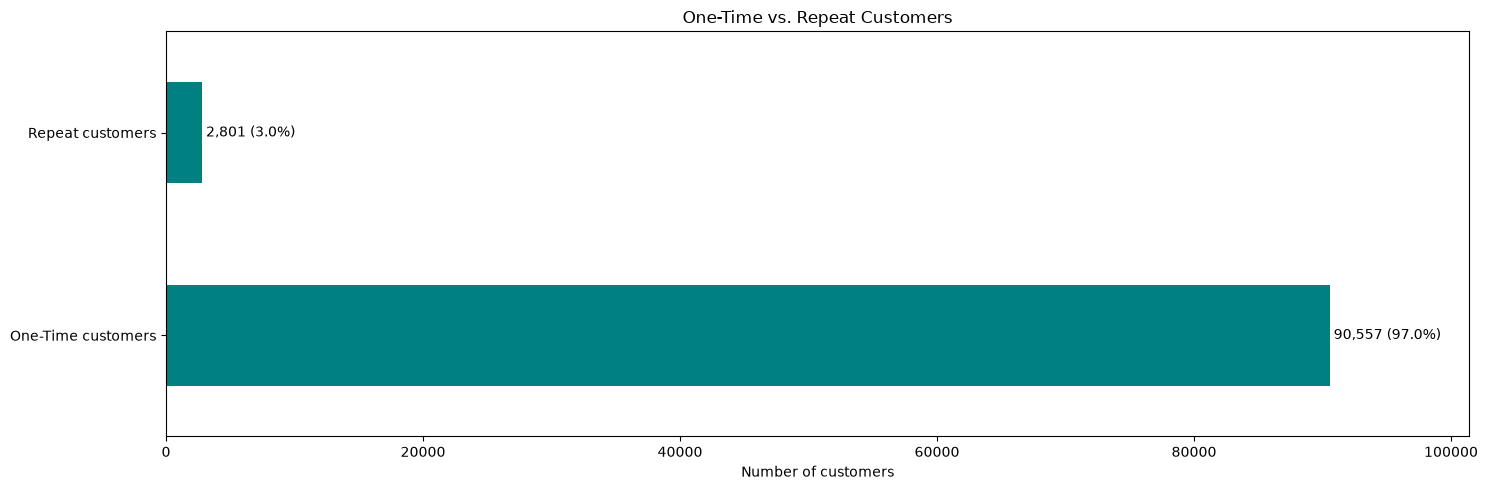

In [245]:
customer_groups = pd.Series({
    "One-Time customers": (orders_per_customer == 1).sum(),
    "Repeat customers": (orders_per_customer > 1).sum(),
})

total_customers = customer_groups.sum()

ax = customer_groups.plot(kind="barh", figsize=(15, 5), color="teal")
ax.set_title("One-Time vs. Repeat Customers")
ax.set_xlabel("Number of customers")
ax.set_ylabel("")
ax.set_xlim(0, customer_groups.max() * 1.12)

for i, count in enumerate(customer_groups):
    percent = count / total_customers * 100
    ax.text(count, i, f" {count:,} ({percent:.1f}%)", va="center")

plt.tight_layout()


<a id="b3"></a>
### B3 · Which customers generate the most sales?

In [246]:
delivered_customer_orders = delivered_orders[["order_id", "customer_unique_id"]]

customer_sales = (
    order_items_df[["order_id", "price"]]
    .merge(
        delivered_customer_orders,
        on="order_id",
        how="inner",
        validate="many_to_one",
    )
    .groupby("customer_unique_id")["price"]
    .sum()
    .sort_values(ascending=False)
)

*The table lists the top 10 customers by total delivered product value.*

In [247]:
top_10_customers = (
    customer_sales.head(10)
    .rename("product_sales_brl")
    .reset_index()
)

display(top_10_customers)

,customer_unique_id,product_sales_brl
0,0a0a92112bd4c708ca5fde585afaa872,13440.0
1,da122df9eeddfedc1dc1f5349a1a690c,7388.0
2,763c8b1c9c68a0229c42c9fc6f662b93,7160.0
3,dc4802a71eae9be1dd28f5d788ceb526,6735.0
4,459bef486812aa25204be022145caa62,6729.0
5,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0
6,4007669dec559734d6f53e029e360987,5934.6
7,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0
8,48e1ac109decbb87765a3eade6854098,4590.0
9,a229eba70ec1c2abef51f04987deb7a5,4400.0


C:\Users\abdel\AppData\Local\Temp\ipykernel_15812\948056078.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


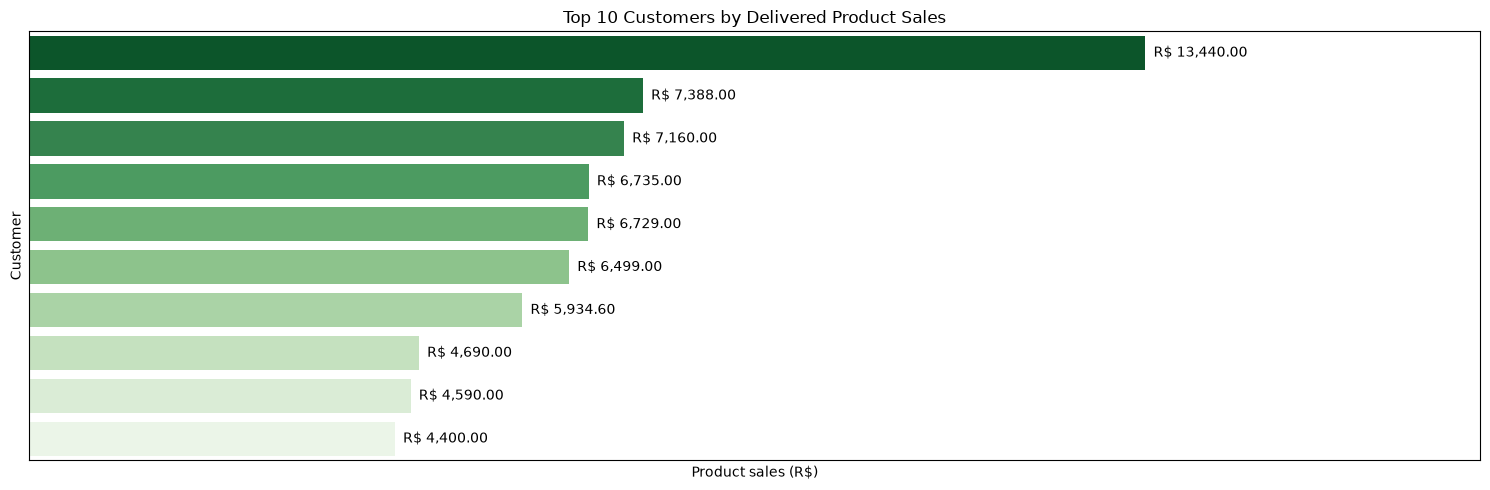

In [248]:
plot_data = top_10_customers.sort_values(
    "product_sales_brl"
)

fig, ax = plt.subplots(figsize=(15, 5))

sns.barplot(
    data=plot_data,
    x="product_sales_brl",
    y="customer_unique_id",
    palette="Greens",
    ax=ax,
)

ax.invert_yaxis()
ax.set_title("Top 10 Customers by Delivered Product Sales")
ax.set_xlabel("Product sales (R$)")
ax.set_ylabel("Customer")
ax.set_yticks([])
ax.set_xticks([])
ax.set_xlim(0, plot_data["product_sales_brl"].max() * 1.3)

for bar in ax.patches:
    ax.text(
        bar.get_width() + 100,
        bar.get_y() + bar.get_height() / 2,
        f"R$ {bar.get_width():,.2f}",
        va="center",
    )


plt.tight_layout()
plt.show()

<a id="b4"></a>
### B4 · Where are Olist's customers located?

In [249]:
customers_by_state = (
    customers_df.groupby("customer_state")["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)


display(customers_by_state.rename("unique_customers").to_frame().head())

,unique_customers
customer_state,
SP,40302
RJ,12384
MG,11259
RS,5277
PR,4882


In [312]:
state_names = {
    "AC": "Acre", "AL": "Alagoas", "AP": "Amapá", "AM": "Amazonas",
    "BA": "Bahia", "CE": "Ceará", "DF": "Distrito Federal",
    "ES": "Espírito Santo", "GO": "Goiás", "MA": "Maranhão",
    "MT": "Mato Grosso", "MS": "Mato Grosso do Sul",
    "MG": "Minas Gerais", "PA": "Pará", "PB": "Paraíba",
    "PR": "Paraná", "PE": "Pernambuco", "PI": "Piauí",
    "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte",
    "RS": "Rio Grande do Sul", "RO": "Rondônia", "RR": "Roraima",
    "SC": "Santa Catarina", "SP": "São Paulo", "SE": "Sergipe",
    "TO": "Tocantins",
}

state_summary = (
    customers_by_state
    .rename("unique_customers")
    .rename_axis("state_code")
    .reset_index()
)

state_summary["state_name"] = state_summary["state_code"].map(state_names)
state_summary = state_summary[["state_code", "state_name", "unique_customers"]]

state_summary

,state_code,state_name,unique_customers
0,SP,São Paulo,40302
1,RJ,Rio de Janeiro,12384
2,MG,Minas Gerais,11259
3,RS,Rio Grande do Sul,5277
4,PR,Paraná,4882
5,SC,Santa Catarina,3534
6,BA,Bahia,3277
7,DF,Distrito Federal,2075
8,ES,Espírito Santo,1964
9,GO,Goiás,1952


C:\Users\abdel\AppData\Local\Temp\ipykernel_15812\478530814.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


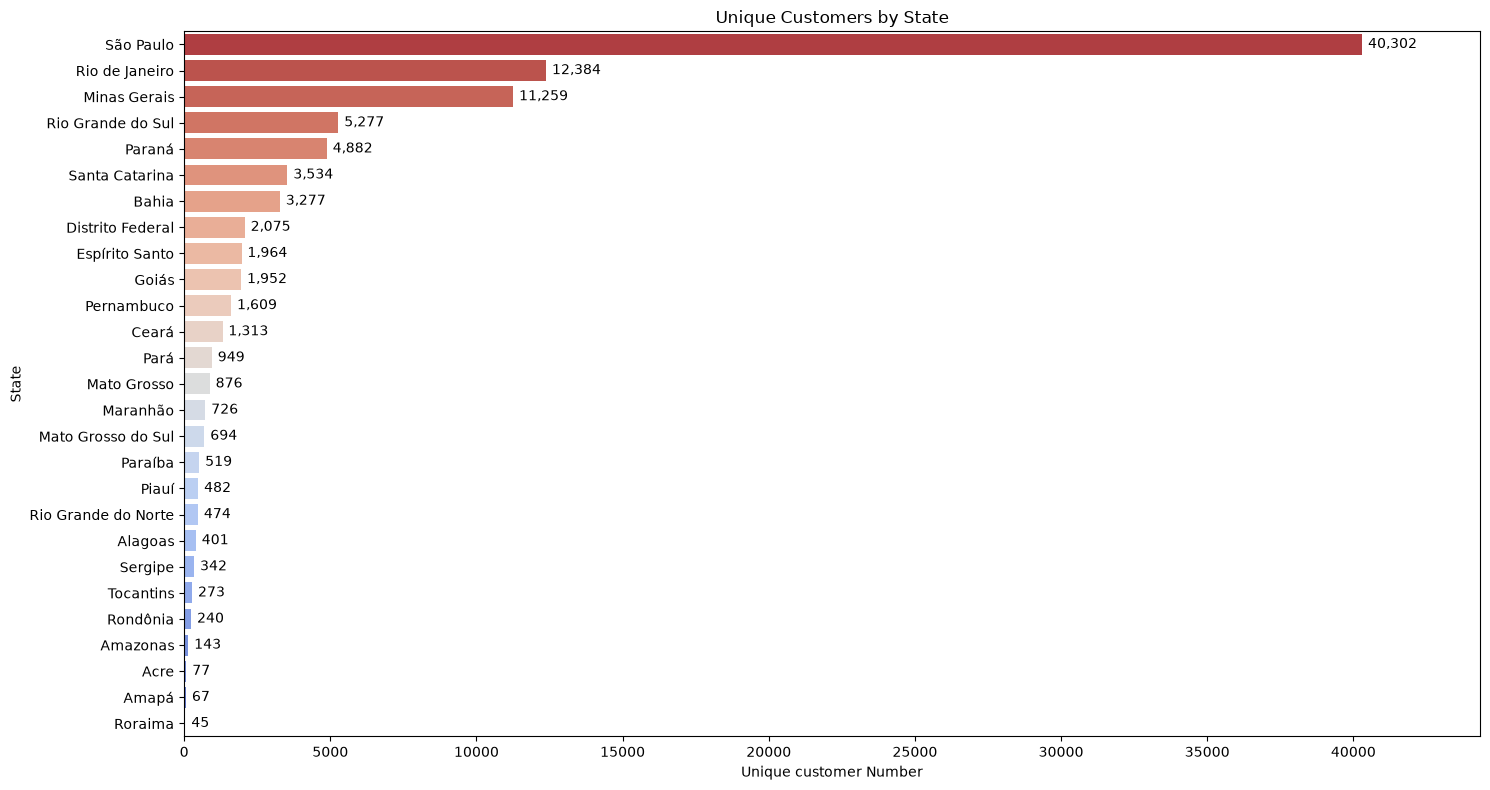

In [251]:
state_data = state_summary.sort_values("unique_customers", ascending=False)

fig, ax = plt.subplots(figsize=(15, 8))

sns.barplot(
    data=state_data,
    x="unique_customers",
    y="state_name",
    palette="coolwarm_r",
    ax=ax,
)

ax.set_title("Unique Customers by State")
ax.set_xlabel("Unique customer Number")
ax.set_ylabel("State")
ax.set_xlim(0, state_data["unique_customers"].max() * 1.1)

for bar in ax.patches:
    ax.text(
        bar.get_width() + 200,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():,.0f}",
        va="center",
    )

plt.tight_layout()
plt.show()

C:\Users\abdel\AppData\Local\Temp\ipykernel_15812\102069559.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


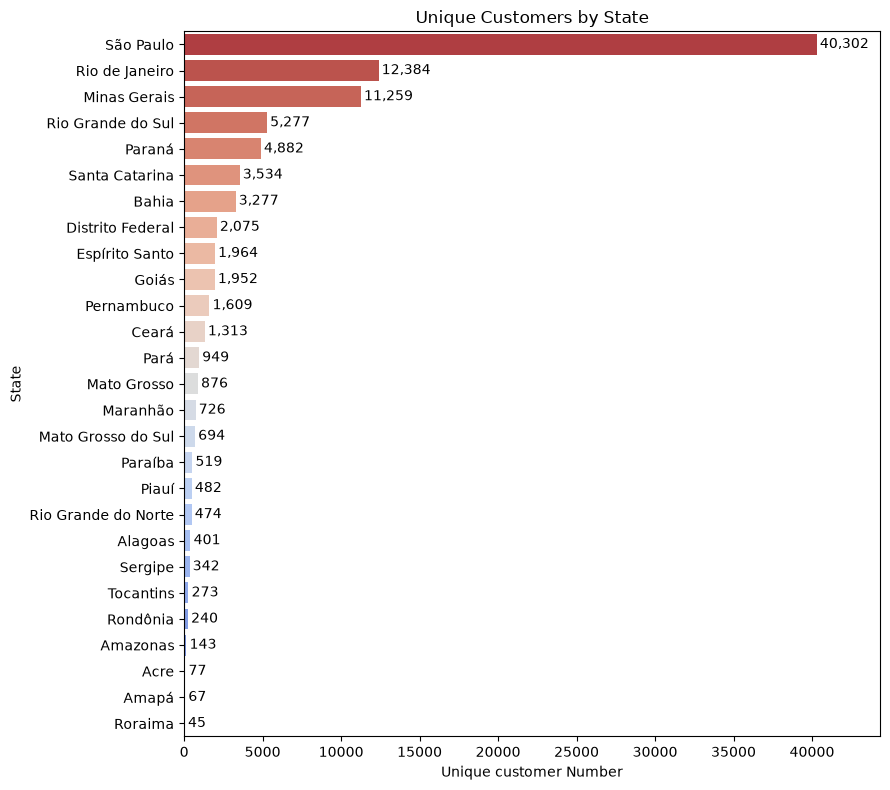

In [313]:
state_data = state_summary.sort_values("unique_customers", ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))

sns.barplot(
    data=state_data,
    x="unique_customers",
    y="state_name",
    palette="coolwarm_r",
    ax=ax,
)

ax.set_title("Unique Customers by State")
ax.set_xlabel("Unique customer Number")
ax.set_ylabel("State")
ax.set_xlim(0, state_data["unique_customers"].max() * 1.1)

for bar in ax.patches:
    ax.text(
        bar.get_width() + 200,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():,.0f}",
        va="center",
    )

plt.tight_layout()
plt.show()

#### Conclusion

The recorded customer locations are concentrated in southeastern Brazil. São Paulo has the most distinct customer IDs (**`40,302`**), followed by Rio de Janeiro (**`12,384`**) and Minas Gerais (**`11,259`**).

A customer ID can appear in more than one state, so the state counts are not additive and should not be compared with the overall unique-customer total as if each person belonged to only one state.

<a id="part-c"></a>
---
## Part C · Product Performance

> **Goal:** Identify the most and least successful products and categories.
>
> **Questions:** C1 Which product categories generate the most sales? · C2 Which categories receive the most orders? · C3 Which categories perform poorly? · C4 Is there a relationship between product categories and customer reviews?

<a id="c1"></a>
### C1 · Which product categories generate the most sales?

In [253]:
category_translation_df.columns.to_list()

['product_category_name', 'product_category_name_english']

In [254]:
products_df.columns.to_list()

['product_id',
 'product_category_name',
 'product_name_lenght',
 'product_description_lenght',
 'product_photos_qty',
 'product_weight_g',
 'product_length_cm',
 'product_height_cm',
 'product_width_cm']

In [255]:
products_with_categories = products_df.merge(
    category_translation_df,
    on="product_category_name",
    how="left",
    validate="many_to_one",
)

products_with_categories = products_with_categories[['product_id','product_category_name','product_category_name_english']]

products_with_categories

,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares
...,...,...,...
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,furniture_decor
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,construction_tools_lights
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,bed_bath_table
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,computers_accessories


In [256]:
order_items_df.columns.to_list()

['order_id',
 'order_item_id',
 'product_id',
 'seller_id',
 'shipping_limit_date',
 'price',
 'freight_value']

In [257]:
products_with_categories_with_items = order_items_df.merge(
    products_with_categories,
    on="product_id",
    how="left",
    validate="many_to_one",
)

products_with_categories_with_items[['order_id', 'order_item_id', 'product_id', 'product_category_name_english', 'price']]

,order_id,order_item_id,product_id,product_category_name_english,price
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.90
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.90
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,furniture_decor,199.00
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,perfumery,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,garden_tools,199.90
...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,housewares,299.99
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,computers_accessories,350.00
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,sports_leisure,99.90
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,computers_accessories,55.99


In [258]:
category_items_with_status = products_with_categories_with_items.merge(
    orders_df[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one",
)

category_items_with_status.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english,order_status
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff,delivered
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop,delivered
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor,delivered
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery,delivered
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools,delivered


In [259]:
delivered_items = category_items_with_status.loc[
    category_items_with_status["order_status"].eq("delivered")
].copy()

delivered_items["product_category_name_english"] = (
    delivered_items["product_category_name_english"].fillna("Unknown")
)

category_sales = (
    delivered_items
    .groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .rename("product_sales_brl")
)

category_sales.head(20).to_frame()

,product_sales_brl
product_category_name_english,
health_beauty,1233131.72
watches_gifts,1166176.98
bed_bath_table,1023434.76
sports_leisure,954852.55
computers_accessories,888724.61
furniture_decor,711927.69
housewares,615628.69
cool_stuff,610204.10
auto,578966.65


C:\Users\abdel\AppData\Local\Temp\ipykernel_15812\2435145562.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


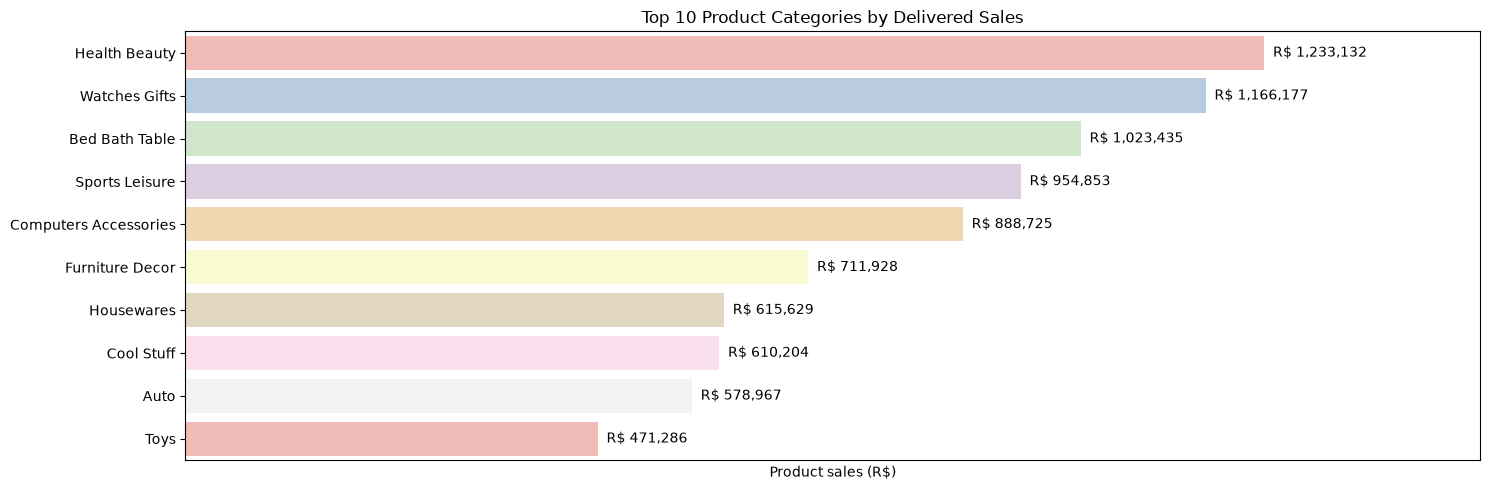

In [260]:
plot_data = (
    category_sales.head(10)
    .sort_values(ascending=False)
    .rename_axis("category")
    .reset_index(name="product_sales_brl")
)

plot_data["category"] = (
    plot_data["category"].str.replace("_", " ", regex=False).str.title()
)

fig, ax = plt.subplots(figsize=(15, 5))

sns.barplot(
    data=plot_data,
    x="product_sales_brl",
    y="category",
    palette=("Pastel1"),
    ax=ax,
)

ax.set_title("Top 10 Product Categories by Delivered Sales")
ax.set_xlabel("Product sales (R$)")
ax.set_ylabel("")
ax.set_xlim(0, plot_data["product_sales_brl"].max() * 1.2)
ax.set_xticks([])

for bar in ax.patches:
    ax.text(
        bar.get_width() + 10_000,
        bar.get_y() + bar.get_height() / 2,
        f"R$ {bar.get_width():,.0f}",
        va="center",
    )

plt.tight_layout()

<a id="c2"></a>
### C2 · Which categories receive the most orders?

In [261]:
items_for_order_counts = products_with_categories_with_items.copy()

items_for_order_counts["product_category_name_english"] = ( items_for_order_counts["product_category_name_english"].fillna("Unknown") )

category_order_counts = (
    items_for_order_counts
    .groupby("product_category_name_english")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("order_count")
)

display(category_order_counts.head(19).to_frame())

,order_count
product_category_name_english,
bed_bath_table,9417
health_beauty,8836
sports_leisure,7720
computers_accessories,6689
furniture_decor,6449
housewares,5884
watches_gifts,5624
telephony,4199
auto,3897


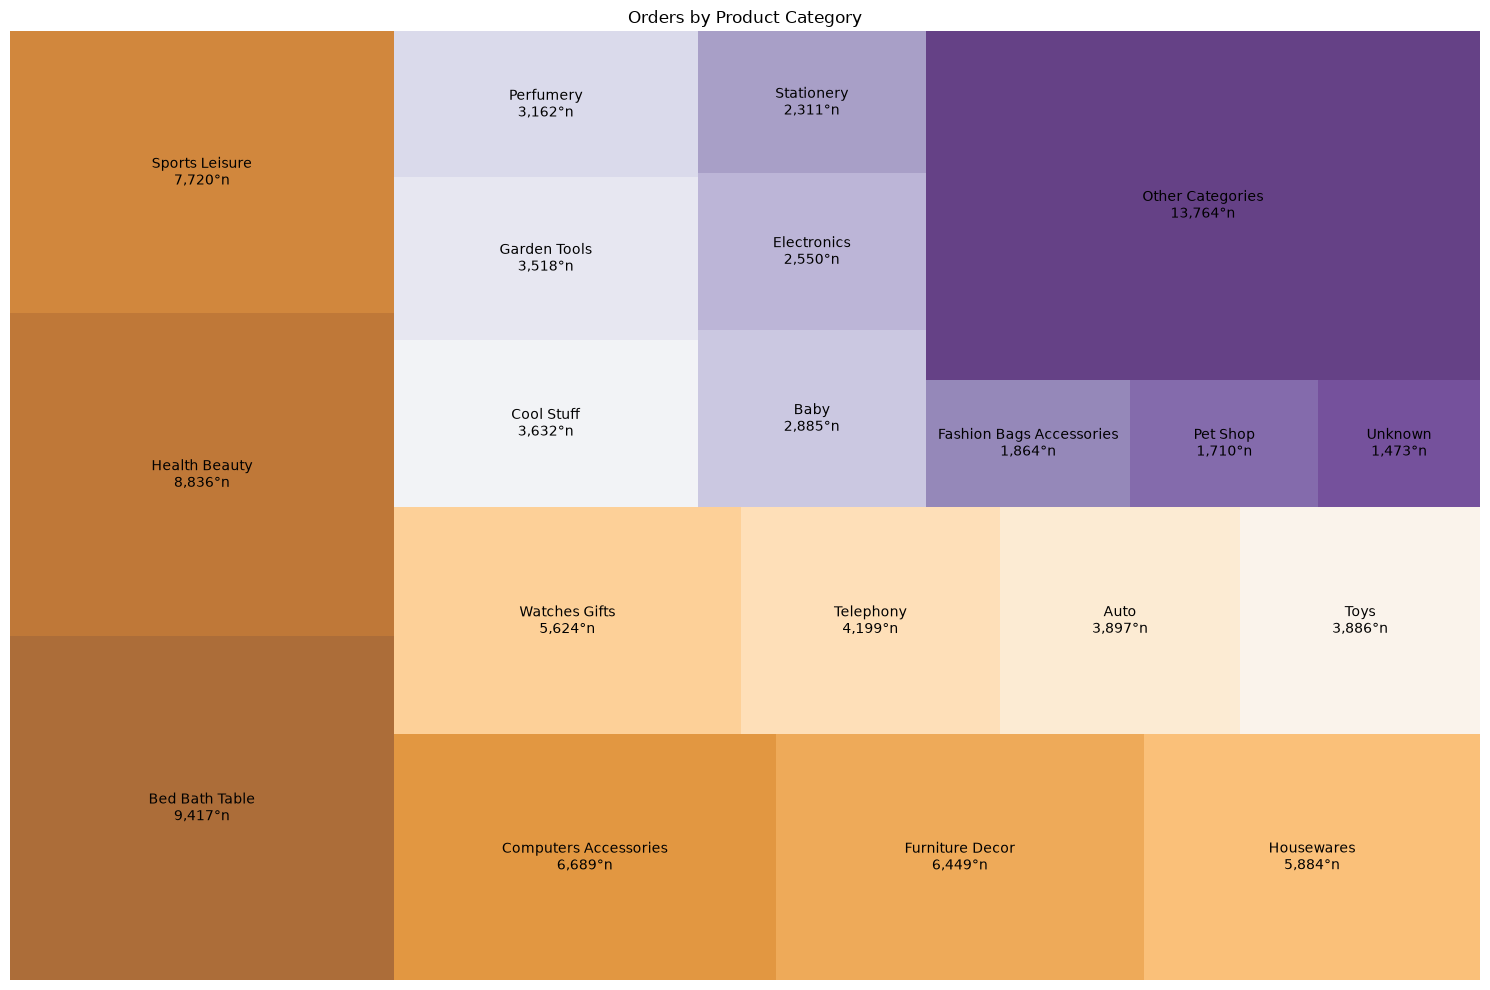

In [262]:
import squarify

known_counts = (
    category_order_counts.sort_values(ascending=False)
)

top_categories = known_counts.head(19)
other_orders = known_counts.iloc[19:].sum()

treemap_data = top_categories.copy()

if other_orders > 0:
    treemap_data.loc["Other categories"] = other_orders

unknown_orders = category_order_counts.get("Unknown", 0)
if unknown_orders > 0:
    treemap_data.loc["Unknown"] = unknown_orders

labels = [
    f"{category.replace('_', ' ').title()}\n{count:,}°n"
    for category, count in treemap_data.items()
]

plt.figure(figsize=(15, 10))
squarify.plot(
    sizes=treemap_data.values,
    label=labels,
    color=sns.color_palette("PuOr", n_colors=len(treemap_data)),
    alpha=0.8,
    text_kwargs={"fontsize": 10},
)
plt.title("Orders by Product Category")
plt.axis("off")
plt.tight_layout()
plt.show()

<a id="c3"></a>
### C3 · Which categories perform poorly?

In [263]:
category_performance = (
    delivered_items
    .groupby("product_category_name_english")
    .agg(
        delivered_sales_brl=("price", "sum"),
        delivered_orders=("order_id", "nunique"),
    )
    .drop(index="Unknown", errors="ignore")
    .sort_values("delivered_sales_brl")
)

display(category_performance.head(10))

,delivered_sales_brl,delivered_orders
product_category_name_english,,
security_and_services,283.29,2
fashion_childrens_clothes,519.95,7
cds_dvds_musicals,730.00,12
home_comfort_2,760.27,24
flowers,1110.04,29
diapers_and_hygiene,1500.79,25
arts_and_craftmanship,1814.01,23
la_cuisine,2054.99,13
fashion_sport,2094.52,26


C:\Users\abdel\AppData\Local\Temp\ipykernel_15812\1447475587.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\abdel\AppData\Local\Temp\ipykernel_15812\1447475587.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


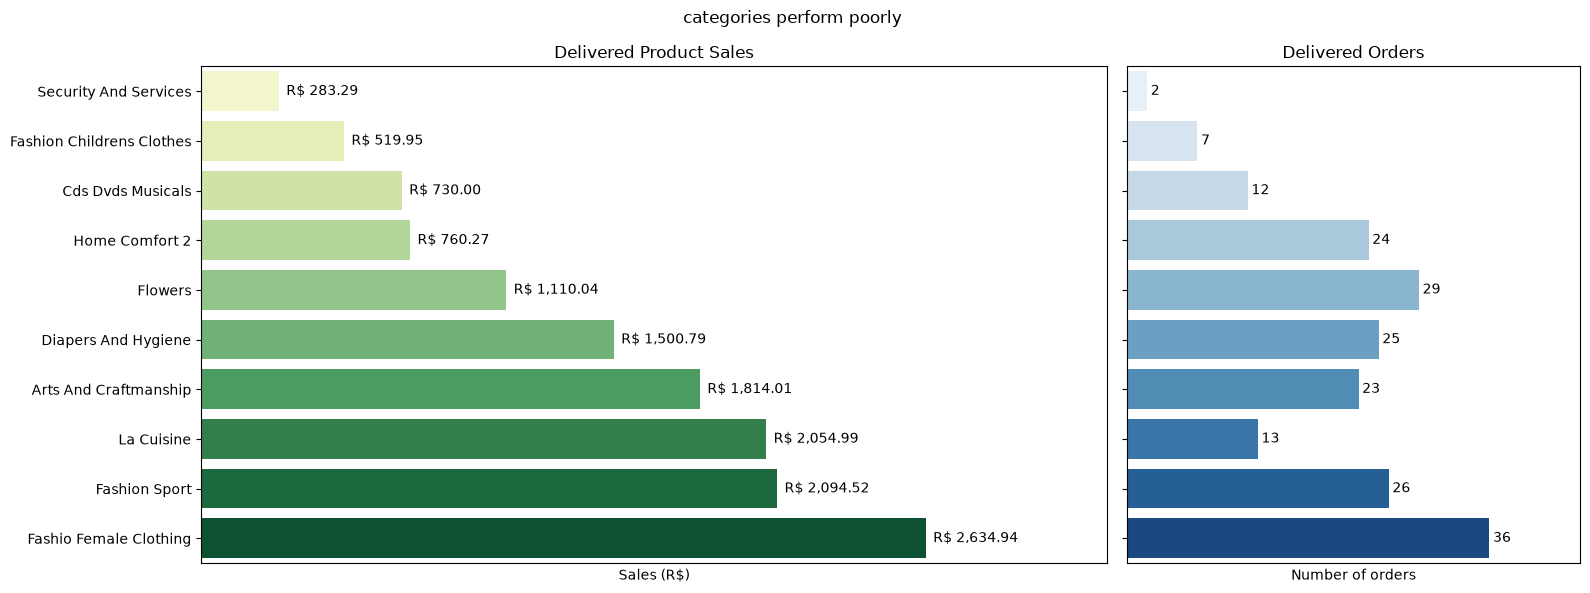

In [264]:
plot_data = category_performance.head(10).reset_index()
plot_data["category"] = (
    plot_data["product_category_name_english"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

plot_data = plot_data.sort_values(by="delivered_sales_brl", ascending=False)

fig, (ax_sales, ax_orders) = plt.subplots(
    ncols=2,
    figsize=(16, 6),
    sharey=True,
    gridspec_kw={"width_ratios": [2, 1]},
)

sns.barplot(
    data=plot_data,
    x="delivered_sales_brl",
    y="category",
    palette="YlGn_r",
    ax=ax_sales,
)

sns.barplot(
    data=plot_data,
    x="delivered_orders",
    y="category",
    palette="Blues_r",
    ax=ax_orders,
)

ax_sales.invert_yaxis()
ax_sales.set_title("Delivered Product Sales")
ax_sales.set_xlabel("Sales (R$)")
ax_sales.set_ylabel("")

ax_orders.set_title("Delivered Orders")
ax_orders.set_xlabel("Number of orders")
ax_orders.set_ylabel("")

ax_sales.set_xticks([])
ax_orders.set_xticks([])

ax_sales.set_xlim(0, plot_data["delivered_sales_brl"].max() * 1.25)
ax_orders.set_xlim(0, plot_data["delivered_orders"].max() * 1.25)

for bar in ax_sales.patches:
    ax_sales.text(
        bar.get_width() + plot_data["delivered_sales_brl"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"R$ {bar.get_width():,.2f}",
        va="center",
    )

for bar in ax_orders.patches:
    ax_orders.text(
        bar.get_width() + plot_data["delivered_orders"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():,.0f}",
        va="center",
    )

fig.suptitle("categories perform poorly ")
plt.tight_layout()
plt.show()

<a id="c4"></a>
### C4 · Is there a relationship between product categories and customer reviews?

In [265]:
order_categories = (
    products_with_categories_with_items.loc[
        products_with_categories_with_items["product_category_name_english"].notna()
        & products_with_categories_with_items["product_category_name_english"].ne("Unknown"),
        ["order_id", "product_category_name_english"],
    ]
    .drop_duplicates()
)

reviews_per_order = (
    order_reviews_df.dropna(subset=["review_score"])
    .groupby("order_id", as_index=False)["review_score"]
    .mean()
)

category_reviews = order_categories.merge(
    reviews_per_order,
    on="order_id",
    how="inner",
    validate="many_to_one",
)

category_review_summary = (
    category_reviews
    .groupby("product_category_name_english")
    .agg(
        average_review_score=("review_score", "mean"),
        reviewed_orders=("order_id", "nunique"),
    )
    .sort_values("average_review_score")
)

display(category_review_summary)

,average_review_score,reviewed_orders
product_category_name_english,,
security_and_services,2.500000,2
office_furniture,3.616390,1263
fashion_male_clothing,3.702703,111
fashio_female_clothing,3.730769,39
diapers_and_hygiene,3.740741,27
...,...,...
books_technical,4.400778,257
costruction_tools_tools,4.425532,94
books_general_interest,4.462598,508


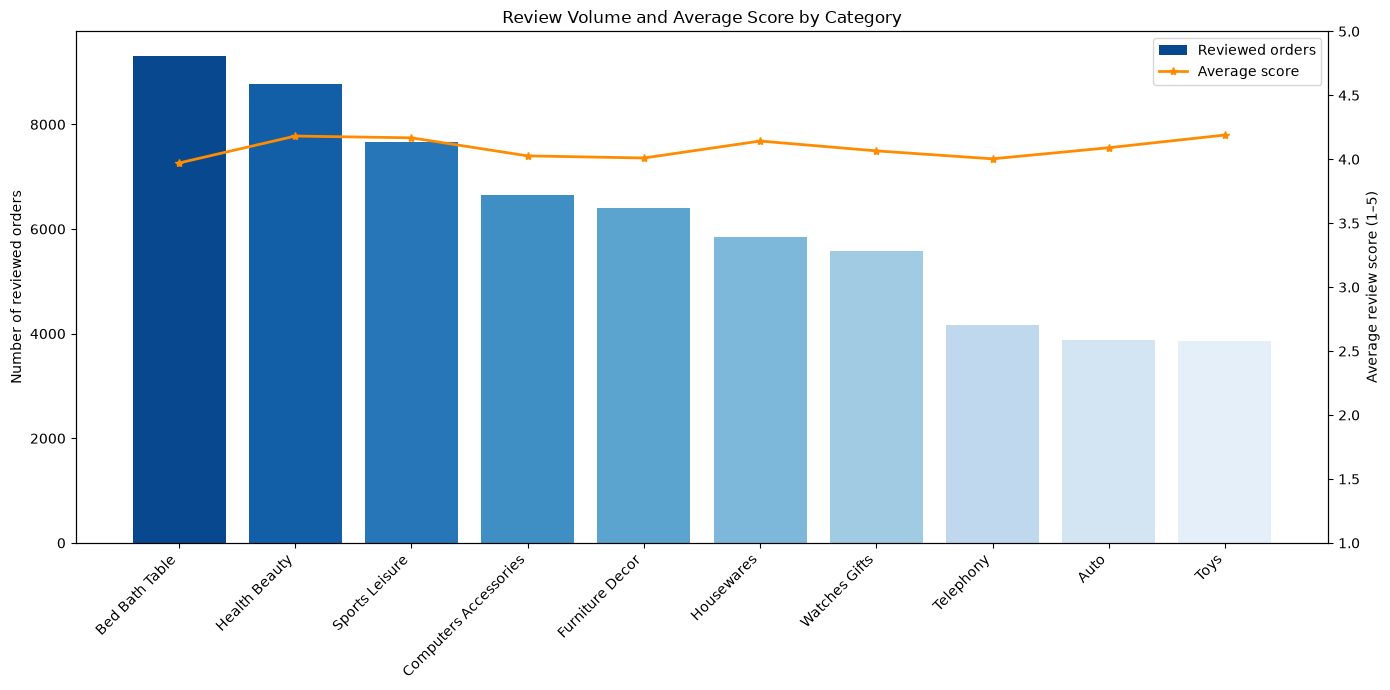

In [266]:
plot_data = category_review_summary.nlargest(10, "reviewed_orders").copy()
categories = plot_data.index.str.replace("_", " ", regex=False).str.title()
x = range(len(plot_data))

fig, ax1 = plt.subplots(figsize=(14, 7))

palette = sns.color_palette("Blues_r", n_colors=len(plot_data))

bars = ax1.bar(x, plot_data["reviewed_orders"], color=palette, label="Reviewed orders")
ax1.set_ylabel("Number of reviewed orders")
ax1.set_xticks(list(x))
ax1.set_xticklabels(categories, rotation=45, ha="right")

ax2 = ax1.twinx()
line, = ax2.plot(
    x, plot_data["average_review_score"],
    color="darkorange", marker="*", linewidth=2, label="Average score"
)
ax2.set_ylabel("Average review score (1–5)")
ax2.set_ylim(1, 5)

ax1.set_title("Review Volume and Average Score by Category")
ax1.legend([bars, line], ["Reviewed orders", "Average score"])

plt.tight_layout()
plt.show()

<a id="part-d"></a>
---
## Part D · Delivery Performance

> **Goal:** Identify delivery problems and measure whether the company meets its estimated delivery dates.
>
> **Questions:** D1 What is the average delivery time? · D2 What percentage of orders arrive late? · D3 Which states or regions have the longest delivery times? · D4 Are late deliveries associated with lower customer satisfaction?

<a id="d1"></a>
### D1 · What is the average delivery time?

*Measured from purchase to customer delivery.*

In [267]:
valid_deliveries = orders_df.loc[
    orders_df["order_status"].eq("delivered")
    & orders_df["order_purchase_timestamp"].notna()
    & orders_df["order_delivered_customer_date"].notna()
].copy()

valid_deliveries.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_timestamp_month,order_purchase_timestamp_year
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,2017
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,2018


In [268]:
valid_deliveries["delivery_days"] = (
    valid_deliveries["order_delivered_customer_date"]   ##we want days
    - valid_deliveries["order_purchase_timestamp"]
).dt.total_seconds() / 86400 

valid_deliveries[["delivery_days"]].head()

,delivery_days
0,8.436574
1,13.782037
2,9.394213
3,13.208750
4,2.873877


In [269]:
print(f"Orders included: {len(valid_deliveries):,}")
print(f"Average delivery time: {valid_deliveries['delivery_days'].mean():.2f} days")

Orders included: 96,470
Average delivery time: 12.56 days


#### Answer

Across **`96,470`** delivered orders with the required timestamps, the average time from purchase to customer delivery was **`12.56` days**. This measures the customer’s end-to-end wait, not just the carrier’s transit time. Delivered orders missing a delivery timestamp were excluded.

<a id="d2"></a>
### D2 · What percentage of orders arrive late?

In [270]:
valid_delivery_dates = orders_df.loc[
    orders_df["order_status"].eq("delivered")
    & orders_df["order_delivered_customer_date"].notna()
    & orders_df["order_estimated_delivery_date"].notna()
]
valid_delivery_dates.head(1)
# filtered dilivered orded with valid dates .

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_timestamp_month,order_purchase_timestamp_year
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,2017


In [271]:
late = (
    valid_delivery_dates["order_delivered_customer_date"]
    > valid_delivery_dates["order_estimated_delivery_date"]
)

late.head(3)   # late dilivred orders

0    False
1    False
2    False
dtype: bool

In [272]:
print(f"Orders evaluated: {len(valid_delivery_dates):,}")
print(f"Late deliveries: {late.sum():,}")
print(f"Late delivery rate: {late.mean():.2%}")

Orders evaluated: 96,470
Late deliveries: 7,826
Late delivery rate: 8.11%


In [273]:
delivery_plot = valid_delivery_dates.dropna(
    subset=["order_purchase_timestamp"]
).copy()

delivery_plot["delivery_days"] = (
    delivery_plot["order_delivered_customer_date"]
    - delivery_plot["order_purchase_timestamp"]
).dt.total_seconds() / 86400

late = (
    delivery_plot["order_delivered_customer_date"]
    > delivery_plot["order_estimated_delivery_date"]
)
delivery_plot["delivery_status"] = late.map({True: "Late", False: "On time"})

C:\Users\abdel\AppData\Local\Temp\ipykernel_15812\1054427516.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


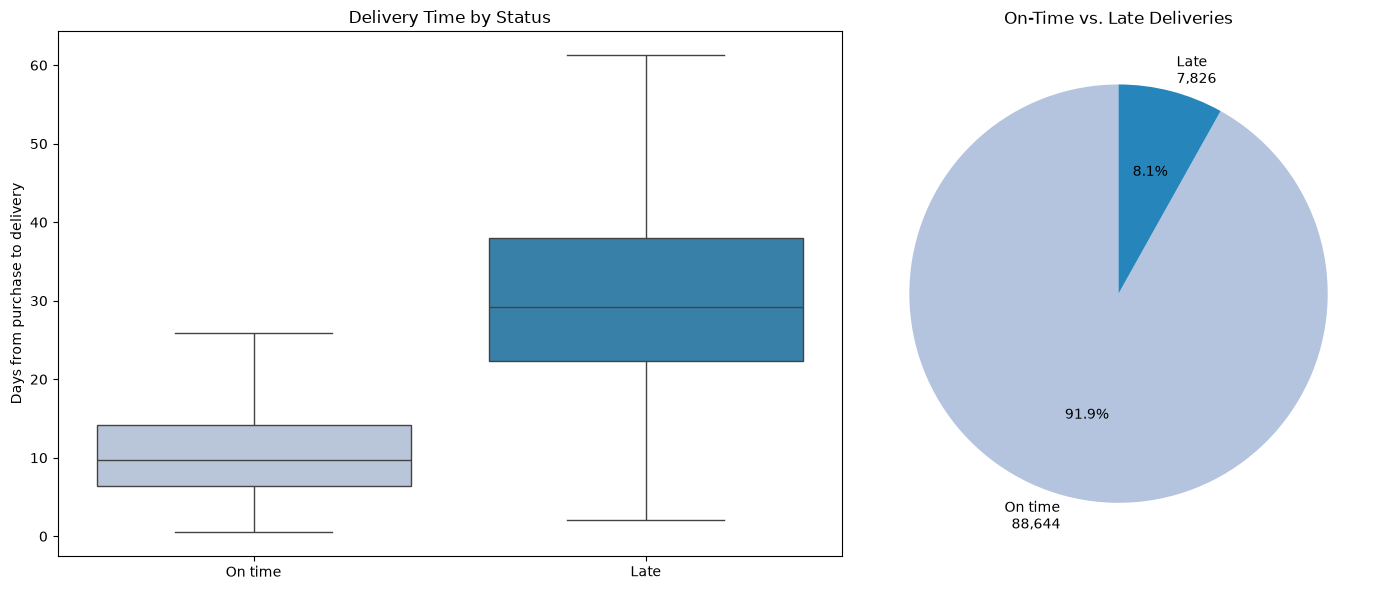

In [274]:
status_counts = delivery_plot["delivery_status"].value_counts().reindex(
    ["On time", "Late"]
)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.5, 1]}
)
delivery_palette = sns.color_palette("PuBu", n_colors=2)

sns.boxplot(
    data=delivery_plot,
    x="delivery_status",
    y="delivery_days",
    order=["On time", "Late"],
    palette=delivery_palette,
    showfliers=False,
    ax=ax1,
)
ax1.set_title("Delivery Time by Status")
ax1.set_xlabel("")
ax1.set_ylabel("Days from purchase to delivery")

ax2.pie(
    status_counts.values,
    labels=[f"{name}\n{count:,}" for name, count in status_counts.items()],
    autopct="%1.1f%%",
    colors=delivery_palette,
    startangle=90,
)
ax2.set_title("On-Time vs. Late Deliveries")

plt.tight_layout()
plt.show()

<a id="d3"></a>
### D3 · Which states or regions have the longest delivery times?

In [275]:
state_delivery = (
    orders_df.loc[
        orders_df["order_status"].eq("delivered"),
        [
            "order_id",
            "customer_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
        ],
    ]
    .dropna(subset=["order_purchase_timestamp", "order_delivered_customer_date"])
    .merge(
        customers_df[["customer_id", "customer_state"]],
        on="customer_id",
        how="left",
    )
    .dropna(subset=["customer_state"])
)

state_delivery.head(3)

,order_id,customer_id,order_purchase_timestamp,order_delivered_customer_date,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-10 21:25:13,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-07 15:27:45,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-08-17 18:06:29,GO


In [276]:
state_delivery["delivery_days"] = (
    state_delivery["order_delivered_customer_date"]
    - state_delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86_400

state_delivery.head(3)

,order_id,customer_id,order_purchase_timestamp,order_delivered_customer_date,customer_state,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-10 21:25:13,SP,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-07 15:27:45,BA,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-08-17 18:06:29,GO,9.394213


In [277]:
state_summary = (
    state_delivery.groupby("customer_state")
    .agg(
        average_delivery_days=("delivery_days", "mean"),
        delivered_orders=("order_id", "nunique"),
    )
    .sort_values("average_delivery_days", ascending=False)
)

state_summary.head(9)

,average_delivery_days,delivered_orders
customer_state,,
RR,29.387546,41
AP,27.185068,67
AM,26.425991,145
AL,24.543855,397
PA,23.772917,946
MA,21.572976,717
SE,21.519788,335
CE,21.266579,1279
AC,21.035713,80


In [278]:
state_names = {
    "AC": "Acre",
    "AL": "Alagoas",
    "AP": "Amapá",
    "AM": "Amazonas",
    "BA": "Bahia",
    "CE": "Ceará",
    "DF": "Distrito Federal",
    "ES": "Espírito Santo",
    "GO": "Goiás",
    "MA": "Maranhão",
    "MT": "Mato Grosso",
    "MS": "Mato Grosso do Sul",
    "MG": "Minas Gerais",
    "PA": "Pará",
    "PB": "Paraíba",
    "PR": "Paraná",
    "PE": "Pernambuco",
    "PI": "Piauí",
    "RJ": "Rio de Janeiro",
    "RN": "Rio Grande do Norte",
    "RS": "Rio Grande do Sul",
    "RO": "Rondônia",
    "RR": "Roraima",
    "SC": "Santa Catarina",
    "SP": "São Paulo",
    "SE": "Sergipe",
    "TO": "Tocantins",
}

state_summary["state_name"] = state_summary.index.map(state_names)
state_summary.head(10)

,average_delivery_days,delivered_orders,state_name
customer_state,,,
RR,29.387546,41,Roraima
AP,27.185068,67,Amapá
AM,26.425991,145,Amazonas
AL,24.543855,397,Alagoas
PA,23.772917,946,Pará
MA,21.572976,717,Maranhão
SE,21.519788,335,Sergipe
CE,21.266579,1279,Ceará
AC,21.035713,80,Acre


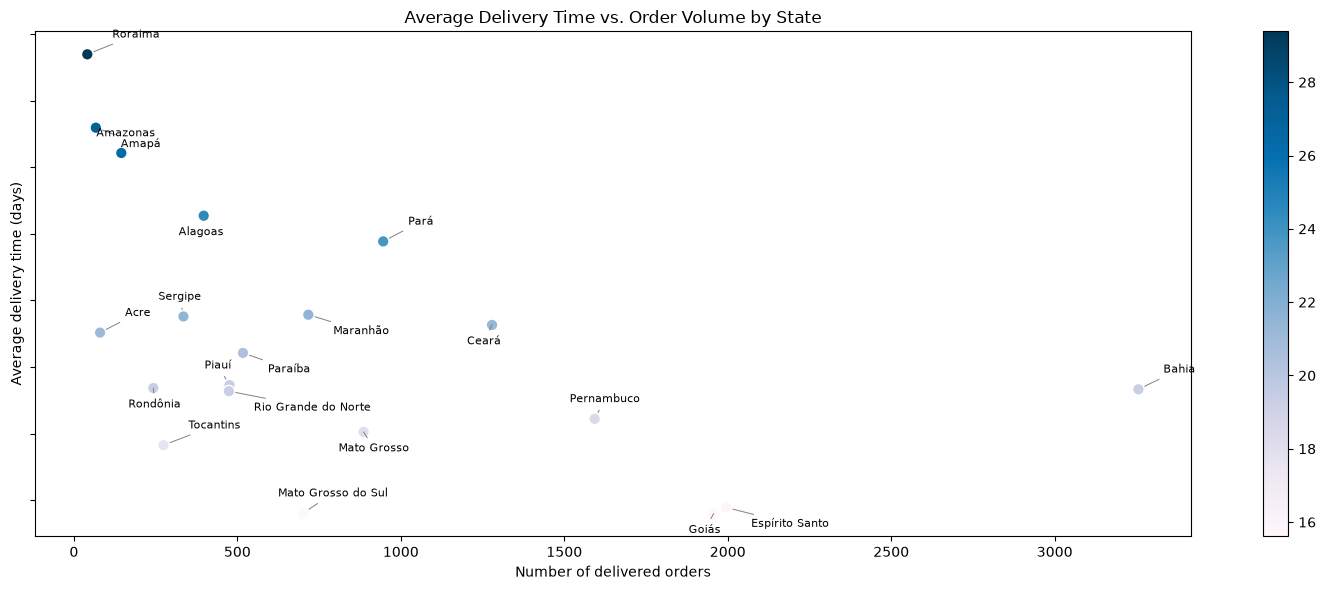

In [279]:
scatter_data = state_summary.head(20).reset_index()

fig, ax = plt.subplots(figsize=(15, 6))

points = ax.scatter(
    scatter_data["delivered_orders"],  
    scatter_data["average_delivery_days"],
    c=scatter_data["average_delivery_days"],
    cmap="PuBu",
    s=70,
    edgecolors="white",
)

offsets = [(18, 12), (18, -14), (-18, 12), (-18, -14)]

for i, (_, row) in enumerate(scatter_data.iterrows()):
    dx, dy = offsets[i % len(offsets)]

    ax.annotate(
        row["state_name"],
        xy=(row["delivered_orders"], row["average_delivery_days"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=8,
        arrowprops={
            "arrowstyle": "-",
            "color": "gray",
            "lw": 0.7,
            "shrinkA": 2,
            "shrinkB": 5,
        },
    )

ax.set_xlabel("Number of delivered orders")
ax.set_ylabel("Average delivery time (days)")
ax.set_title("Average Delivery Time vs. Order Volume by State")
ax.tick_params(axis="y", labelleft=False)

colorbar = fig.colorbar(points, ax=ax)
colorbar.set_label("")

plt.tight_layout()
plt.show()

<a id="d4"></a>
### D4 · Are late deliveries associated with lower customer satisfaction?

In [280]:
reviews_per_order = (
    order_reviews_df.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)
reviews_per_order.head()

,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0


In [281]:
delivery_reviews = (
    orders_df.loc[
        orders_df["order_status"].eq("delivered"),
        [
            "order_id",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
        ],
    ]
    .dropna(
        subset=[
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
        ]
    )
    .merge(reviews_per_order, on="order_id", how="inner", validate="one_to_one")
    .dropna(subset=["review_score"])
)
delivery_reviews.head()

,order_id,order_delivered_customer_date,order_estimated_delivery_date,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,5.0


In [282]:
delivery_reviews["delivery_status"] = (
    delivery_reviews["order_delivered_customer_date"]
    .gt(delivery_reviews["order_estimated_delivery_date"])
    .map({True: "Late", False: "On time"})
)
delivery_reviews.head()

,order_id,order_delivered_customer_date,order_estimated_delivery_date,review_score,delivery_status
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,4.0,On time
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,4.0,On time
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,5.0,On time
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,5.0,On time
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,5.0,On time


In [283]:
review_comparison = (
    delivery_reviews.groupby("delivery_status")
    .agg(
        reviewed_orders=("order_id", "nunique"),
        average_review_score=("review_score", "mean"),
        median_review_score=("review_score", "median"),
    )
    .round(2)
)

review_comparison

,reviewed_orders,average_review_score,median_review_score
delivery_status,,,
Late,7661,2.57,2.0
On time,88163,4.29,5.0


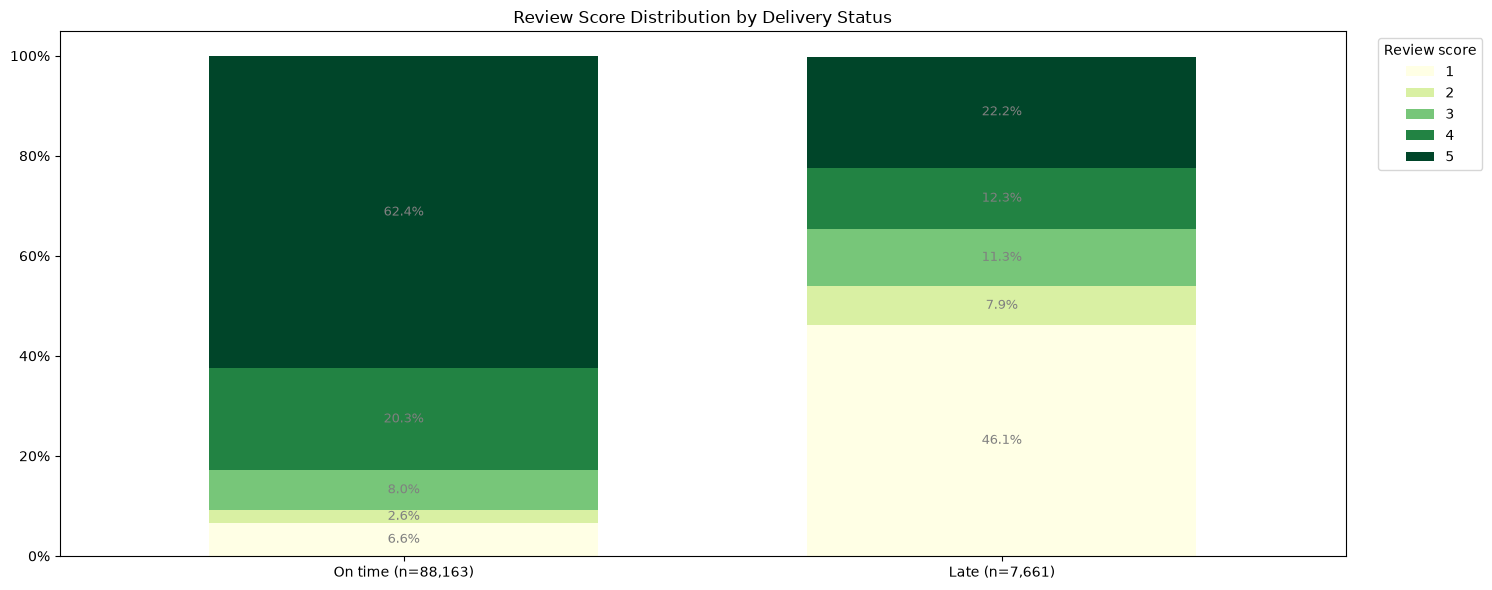

In [284]:
score_distribution = pd.crosstab(
    delivery_reviews["delivery_status"],
    delivery_reviews["review_score"],
    normalize="index",
).reindex(index=["On time", "Late"], columns=[1, 2, 3, 4, 5], fill_value=0)

ax = score_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 6),
    colormap="YlGn",
    width=0.65,
)

for container, score in zip(ax.containers, score_distribution.columns):
    labels = [
        f"{value:.1%}" if value > 0 else ""
        for value in score_distribution[score]
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
        color="gray",
    )

ax.set_xticklabels(["On time (n=88,163)", "Late (n=7,661)"], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Review Score Distribution by Delivery Status")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend(title="Review score", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

<a id="part-e"></a>
---
## Part E · Payment Analysis

> **Goal:** Understand how customers pay: which methods dominate, how much value they carry and how installments are used.
>
> **Questions:** E1 Which payment methods are used most often? · E2 Which methods account for the greatest total payment value? · E3 How does installment use vary by payment method? · E4 For credit-card payments, how does payment value vary with the number of installments?

<a id="e1"></a>
### E1 · Which payment methods are used most often?

In [285]:
payments = order_payments_df.dropna( subset=["order_id", "payment_type"] ).copy()

total_orders = payments["order_id"].nunique()

payment_method_summary = (
    payments.groupby("payment_type")
    .agg( payment_records=("order_id", "size"), orders_using_method=("order_id", "nunique"),)
    .assign(
        order_share_pct=lambda df: (df["orders_using_method"] / total_orders * 100 ).round(2)
    )
    .sort_values("orders_using_method", ascending=False)
)

payment_method_summary

,payment_records,orders_using_method,order_share_pct
payment_type,,,
credit_card,76795,76505,76.94
boleto,19784,19784,19.90
voucher,5775,3866,3.89
debit_card,1529,1528,1.54
not_defined,3,3,0.00


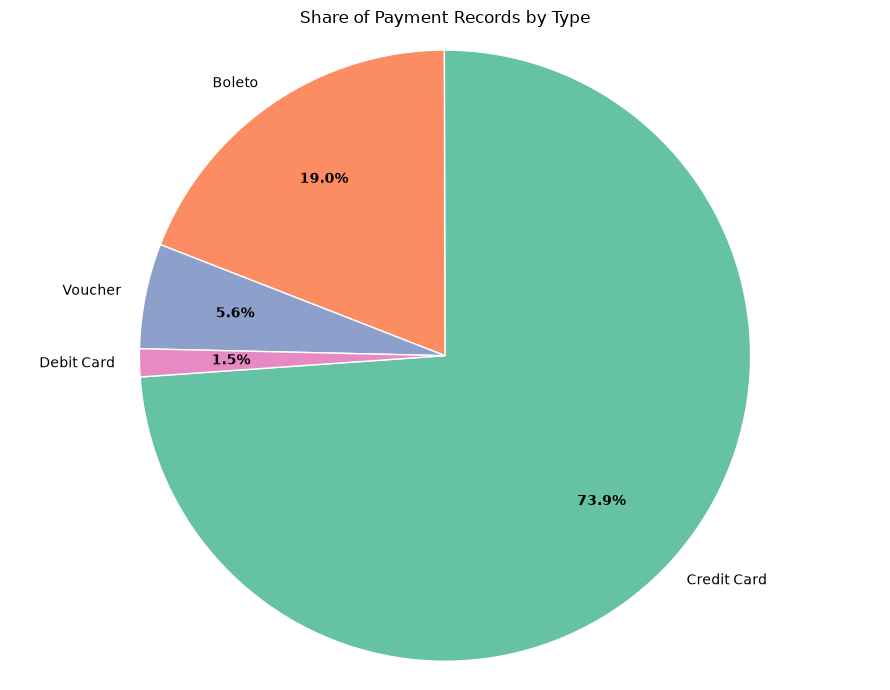

In [286]:
payment_counts = (
    payment_method_summary.loc[
        payment_method_summary.index != "not_defined",
        "payment_records",
    ]
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 7))

wedges, labels, percentages = ax.pie(
    payment_counts,
    labels=payment_counts.index.str.replace("_", " ").str.title(),
    autopct="%1.1f%%",
    startangle=184,
    colors=sns.color_palette("Set2", n_colors=len(payment_counts)),
    labeldistance=1.08,
    pctdistance=0.7,
    wedgeprops={"edgecolor": "white", "linewidth": 1},
)

for text in percentages:
    text.set_fontweight("bold")

ax.set_title("Share of Payment Records by Type")
ax.axis("equal")

plt.tight_layout()
fig.savefig("Plots/13_E_payment_records_share.png", dpi=300, bbox_inches="tight")
plt.show()

<a id="e2"></a>
### E2 · Which payment methods account for the greatest total payment value?

In [287]:
payments = order_payments_df.dropna( subset=["payment_type", "payment_value"] ).copy()

total_payment_value = payments["payment_value"].sum()

payment_value_summary = (
    payments.groupby("payment_type")
    .agg( total_payment_value=("payment_value", "sum"), payment_records=("payment_value", "size"),  orders_using_method=("order_id", "nunique"), )
    .assign(
        payment_value_share_pct=lambda df: ( df["total_payment_value"] / total_payment_value * 100 ).round(2)
    )
    .sort_values("total_payment_value", ascending=False)
)

payment_value_summary

,total_payment_value,payment_records,orders_using_method,payment_value_share_pct
payment_type,,,,
credit_card,12542084.19,76795,76505,78.34
boleto,2869361.27,19784,19784,17.92
voucher,379436.87,5775,3866,2.37
debit_card,217989.79,1529,1528,1.36
not_defined,0.00,3,3,0.00


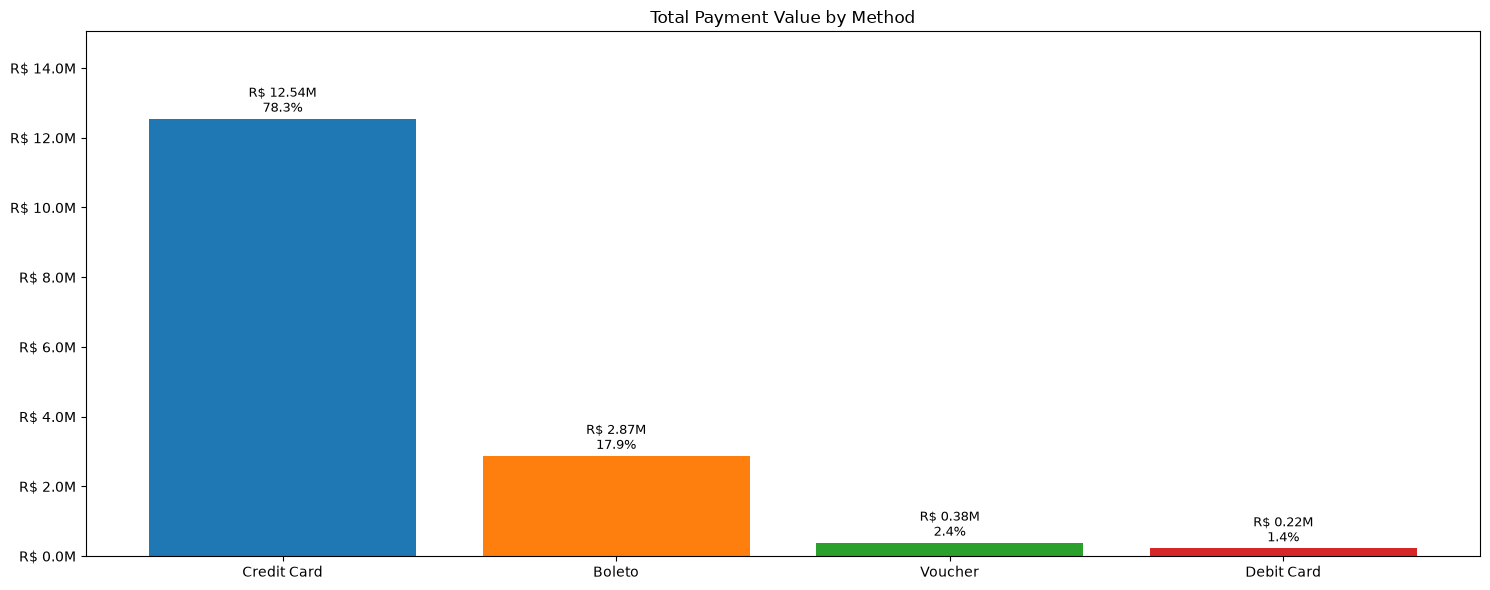

In [288]:
plot_data = (
    payment_value_summary.loc[
        payment_value_summary["total_payment_value"] > 0
    ]
    .sort_values("total_payment_value", ascending=False)
)

total_value = payment_value_summary["total_payment_value"].sum()
labels = [method.replace("_", " ").title() for method in plot_data.index]

fig, ax = plt.subplots(figsize=(15, 6))

bars = ax.bar(
    labels,
    plot_data["total_payment_value"],
    color=sns.color_palette("tab10", n_colors=len(plot_data)),
)

for bar, value in zip(bars, plot_data["total_payment_value"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + total_value * 0.005,
        f"R$ {value / 1_000_000:.2f}M\n{value / total_value:.1%}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Total Payment Value by Method")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"R$ {value / 1_000_000:.1f}M")
)
ax.set_ylim(0, plot_data["total_payment_value"].max() * 1.2)

plt.tight_layout()
plt.show()

<a id="e3"></a>
### E3 · How does installment use vary by payment method?

In [289]:
payments = order_payments_df.dropna(subset=["payment_type", "payment_installments"] ).copy()

payments = payments.loc[payments["payment_type"] != "not_defined"]
payments["has_installments"] = payments["payment_installments"] > 1

installment_summary = (
    payments.groupby("payment_type")
    .agg(
        payment_records=("order_id", "size"),
        records_with_installments=("has_installments", "sum"),
        average_installments=("payment_installments", "mean"),
        median_installments=("payment_installments", "median"),
    )
    .assign(
        installment_usage_pct=lambda df: (
            df["records_with_installments"] / df["payment_records"] * 100
        )
    )
    .round(2)
    .sort_values("installment_usage_pct", ascending=False)
)

installment_summary

,payment_records,records_with_installments,average_installments,median_installments,installment_usage_pct
payment_type,,,,,
credit_card,76795,51338,3.51,3.0,66.85
boleto,19784,0,1.00,1.0,0.00
debit_card,1529,0,1.00,1.0,0.00
voucher,5775,0,1.00,1.0,0.00


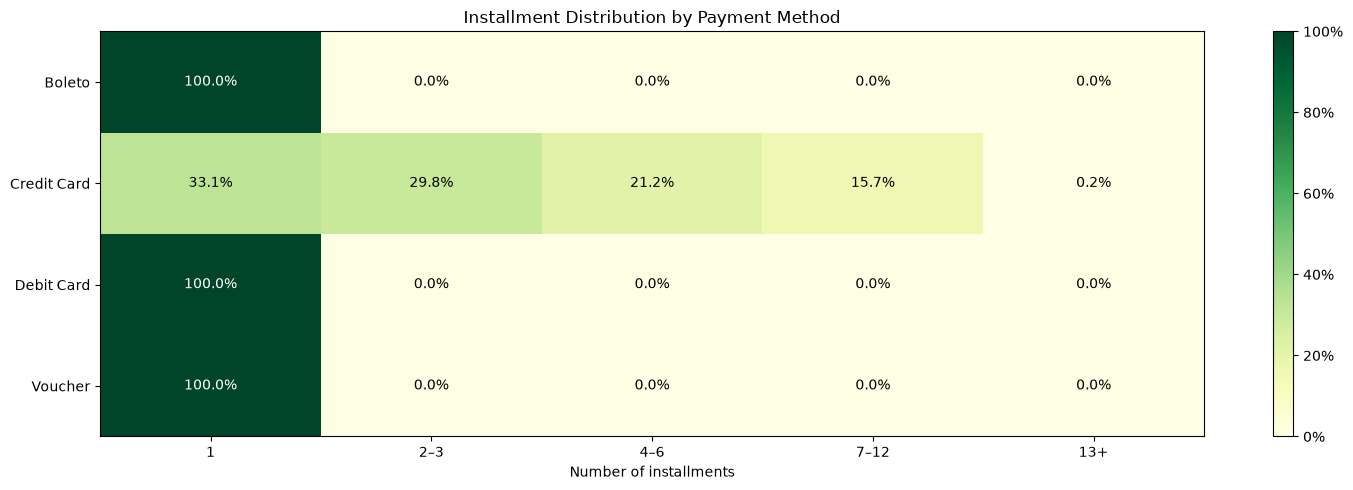

In [290]:
installment_payments = order_payments_df.loc[
    order_payments_df["payment_type"].notna()
    & order_payments_df["payment_type"].ne("not_defined")
    & order_payments_df["payment_installments"].ge(1)
].copy()

installment_ranges = ["1", "2–3", "4–6", "7–12", "13+"]

installment_payments["installment_range"] = pd.cut(
    installment_payments["payment_installments"],
    bins=[0, 1, 3, 6, 12, float("inf")],
    labels=installment_ranges,
)

installment_matrix = pd.crosstab(
    installment_payments["payment_type"],
    installment_payments["installment_range"],
    normalize="index",
).reindex(columns=installment_ranges, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(15, 5))

image = ax.imshow(
    installment_matrix.values,
    cmap="YlGn",
    aspect="auto",
    vmin=0,
    vmax=100,
)

ax.set_xticks(range(len(installment_ranges)))
ax.set_xticklabels(installment_ranges)
ax.set_yticks(range(len(installment_matrix.index)))
ax.set_yticklabels(
    [method.replace("_", " ").title() for method in installment_matrix.index]
)

for row in range(installment_matrix.shape[0]):
    for col in range(installment_matrix.shape[1]):
        value = installment_matrix.iloc[row, col]
        ax.text(
            col,
            row,
            f"{value:.1f}%",
            ha="center",
            va="center",
            color="white" if value >= 50 else "black",
        )

ax.set_xlabel("Number of installments")
ax.set_ylabel("")
ax.set_title("Installment Distribution by Payment Method")

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("")
colorbar.ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0f}%")
)

plt.tight_layout()
plt.show()

<a id="e4"></a>
### E4 · For credit-card payments, how does payment value vary with the number of installments?

In [291]:
credit_card_payments = (
    order_payments_df.loc[
        order_payments_df["payment_type"].eq("credit_card"),
        ["order_id", "payment_installments", "payment_value"],
    ]
    .dropna(subset=["payment_installments", "payment_value"])
)
credit_card_payments.head(2)

,order_id,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,24.39


In [292]:
credit_card_payments = credit_card_payments.loc[credit_card_payments["payment_installments"] >= 1 ]

credit_card_payments.head(2)

,order_id,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,24.39


In [293]:
credit_card_installment_summary = (
    credit_card_payments.groupby("payment_installments")
    .agg(
        payment_records=("order_id", "size"),
        median_payment_value=("payment_value", "median"),
        average_payment_value=("payment_value", "mean"),
    )
    .sort_index()
    .round(2)
)

credit_card_installment_summary.head(2)

,payment_records,median_payment_value,average_payment_value
payment_installments,,,
1,25455,67.87,95.87
2,12413,109.42,127.23


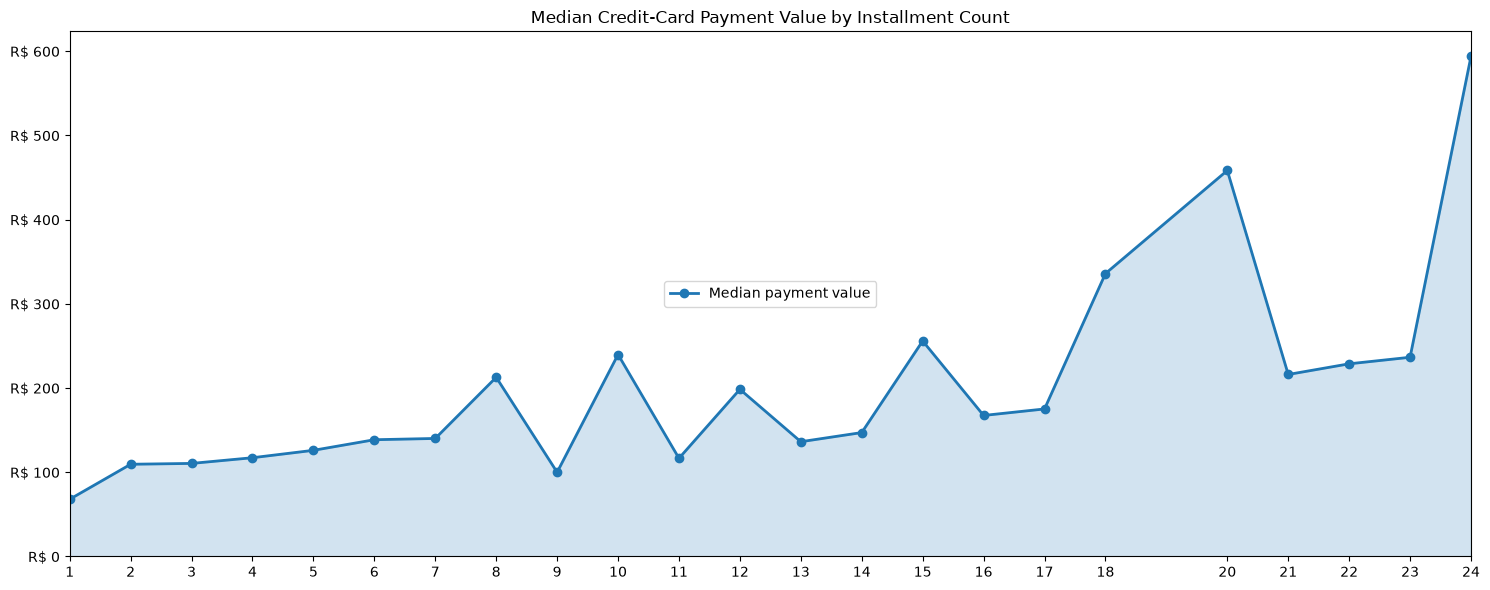

In [294]:
plot_data = credit_card_installment_summary.sort_index()
x = plot_data.index.to_numpy(dtype=float)
median_values = plot_data["median_payment_value"].to_numpy()
color = sns.color_palette("tab10")[0]

fig, ax = plt.subplots(figsize=(15, 6))

ax.fill_between(x, median_values, 0, color=color, alpha=0.2)
ax.plot(
    x,
    median_values,
    color=color,
    marker="o",
    linewidth=2,
    label="Median payment value",
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Median Credit-Card Payment Value by Installment Count")
ax.set_xticks(x)
ax.set_xlim(1, 24)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"R$ {value:,.0f}")
)
ax.legend(
    loc="center",
)
plt.tight_layout()
plt.show()

<a id="part-f"></a>
---
## Part F · Seller Performance

> **Goal:** Evaluate the performance of sellers using the Olist marketplace.
>
> **Questions:** F1 Who are the top-performing sellers, and which generate the highest sales? · F2 How does delivery performance compare across sellers? · F3 Does the seller's state relate to delivery time or lateness? · F4 Do some sellers consistently receive poor reviews?

<a id="f1"></a>
### F1 · Who are the top-performing sellers, and which generate the highest sales?

In [295]:
delivered_order_ids = orders_df.loc[
    orders_df["order_status"].eq("delivered"),
    ["order_id"],
]

delivered_order_ids.head(2)

,order_id
0,e481f51cbdc54678b7cc49136f2d6af7
1,53cdb2fc8bc7dce0b6741e2150273451


In [296]:
delivered_seller_items = order_items_df.merge(
    delivered_order_ids,
    on="order_id",
    how="inner",
    validate="many_to_one",
)

delivered_seller_items.head(2)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


In [297]:
seller_summary = (
    delivered_seller_items.groupby("seller_id", as_index=False)
    .agg(
        delivered_product_sales=("price", "sum"),
        delivered_orders=("order_id", "nunique"),
        items_sold=("order_id", "size"),
    )
    .merge(
        sellers_df[["seller_id", "seller_city", "seller_state"]],
        on="seller_id",
        how="left",
        validate="one_to_one",
    )
)

seller_summary.head(2)

,seller_id,delivered_product_sales,delivered_orders,items_sold,seller_city,seller_state
0,0015a82c2db000af6aaaf3ae2ecb0532,2685.00,3,3,santo andre,SP
1,001cca7ae9ae17fb1caed9dfb1094831,24487.03,195,234,cariacica,ES


In [298]:
top_10_by_sales = (
    seller_summary.nlargest(10, "delivered_product_sales")
    .reset_index(drop=True)
)
top_10_by_sales

,seller_id,delivered_product_sales,delivered_orders,items_sold,seller_city,seller_state
0,4869f7a5dfa277a7dca6462dcf3b52b2,226987.93,1124,1148,guariba,SP
1,53243585a1d6dc2643021fd1853d8905,217940.44,348,400,lauro de freitas,BA
2,4a3ca9315b744ce9f8e9374361493884,196882.12,1772,1949,ibitinga,SP
3,fa1c13f2614d7b5c4749cbc52fecda94,190917.14,578,579,sumare,SP
4,7c67e1448b00f6e969d365cea6b010ab,186570.05,973,1355,itaquaquecetuba,SP
5,7e93a43ef30c4f03f38b393420bc753a,165981.49,319,322,barueri,SP
6,da8622b14eb17ae2831f4ac5b9dab84a,159816.87,1311,1548,piracicaba,SP
7,7a67c85e85bb2ce8582c35f2203ad736,139658.69,1145,1155,sao paulo,SP
8,1025f0e2d44d7041d6cf58b6550e0bfa,138208.56,910,1420,sao paulo,SP
9,955fee9216a65b617aa5c0531780ce60,131836.71,1261,1472,sao paulo,SP


In [299]:

top_10_by_orders = (
    seller_summary.nlargest(10, "delivered_orders")
    .reset_index(drop=True)
)
top_10_by_orders

,seller_id,delivered_product_sales,delivered_orders,items_sold,seller_city,seller_state
0,6560211a19b47992c3666cc44a7e94c0,120702.83,1819,1996,sao paulo,SP
1,4a3ca9315b744ce9f8e9374361493884,196882.12,1772,1949,ibitinga,SP
2,cc419e0650a3c5ba77189a1882b7556a,101090.96,1651,1719,santo andre,SP
3,1f50f920176fa81dab994f9023523100,106655.71,1399,1926,sao jose do rio preto,SP
4,da8622b14eb17ae2831f4ac5b9dab84a,159816.87,1311,1548,piracicaba,SP
5,955fee9216a65b617aa5c0531780ce60,131836.71,1261,1472,sao paulo,SP
6,7a67c85e85bb2ce8582c35f2203ad736,139658.69,1145,1155,sao paulo,SP
7,ea8482cd71df3c1969d7b9473ff13abc,36696.76,1132,1188,sao paulo,SP
8,4869f7a5dfa277a7dca6462dcf3b52b2,226987.93,1124,1148,guariba,SP
9,3d871de0142ce09b7081e2b9d1733cb1,93407.40,1064,1131,campo limpo paulista,SP


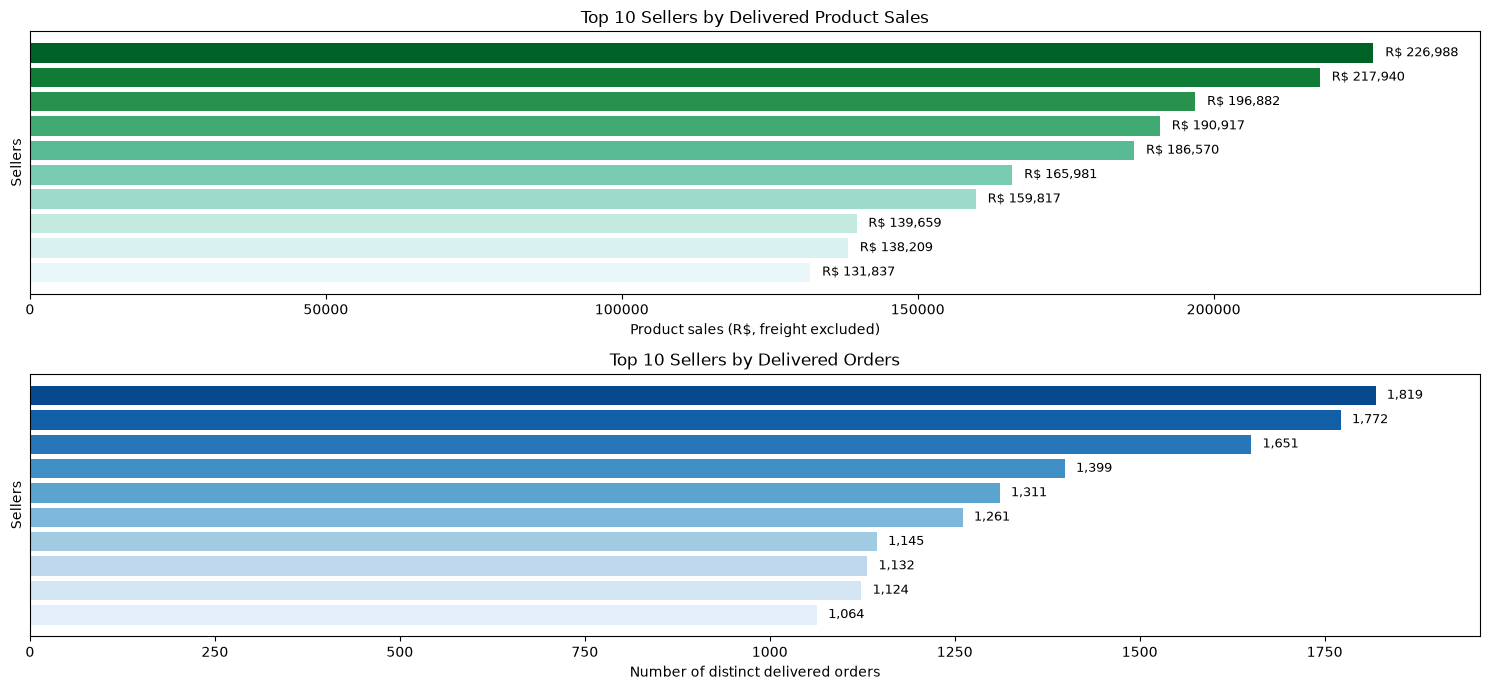

In [300]:
sales_plot = top_10_by_sales.sort_values("delivered_product_sales")
orders_plot = top_10_by_orders.sort_values("delivered_orders")

fig, axes = plt.subplots(2, 1, figsize=(15, 7))

sales_bars = axes[0].barh(
    range(len(sales_plot)),
    sales_plot["delivered_product_sales"],
    color=sns.color_palette("BuGn", n_colors=len(sales_plot)),
)

for bar, value in zip(sales_bars, sales_plot["delivered_product_sales"]):
    axes[0].text(
        bar.get_width() + 2000,
        bar.get_y() + bar.get_height() / 2,
        f"R$ {value:,.0f}",
        va="center",
        fontsize=9,
    )

axes[0].set_title("Top 10 Sellers by Delivered Product Sales")
axes[0].set_xlabel("Product sales (R$, freight excluded)")
axes[0].set_xlim(0, 245000)
axes[0].set_yticks([])
axes[0].set_ylabel("Sellers")


order_bars = axes[1].barh(
    range(len(orders_plot)),
    orders_plot["delivered_orders"],
    color=sns.color_palette("Blues", n_colors=len(orders_plot)),
)

for bar, value in zip(order_bars, orders_plot["delivered_orders"]):
    axes[1].text(
        bar.get_width() + 15,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center",
        fontsize=9,
    )

axes[1].set_title("Top 10 Sellers by Delivered Orders")
axes[1].set_xlabel("Number of distinct delivered orders")
axes[1].set_xlim(0, 1960)
axes[1].set_yticks([])
axes[1].set_ylabel("")
axes[1].set_ylabel("Sellers")


fig.tight_layout()
plt.show()

<a id="f2"></a>
### F2 · How does delivery performance compare across sellers?

In [301]:
seller_orders = (
    order_items_df[["order_id", "seller_id"]]
    .dropna(subset=["seller_id"])
    .drop_duplicates(["order_id", "seller_id"])
    .merge(
        orders_df.loc[
            orders_df["order_status"].eq("delivered"),
            [
                "order_id",
                "order_purchase_timestamp",
                "order_delivered_customer_date",
                "order_estimated_delivery_date",
            ],
        ].dropna(
            subset=[
                "order_purchase_timestamp",
                "order_delivered_customer_date",
                "order_estimated_delivery_date",
            ]
        ),
        on="order_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        sellers_df[["seller_id", "seller_city", "seller_state"]],
        on="seller_id",
        how="left",
        validate="many_to_one",
    )
)

seller_orders.head(3)

,order_id,seller_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,seller_city,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,volta redonda,SP
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,borda da mata,MG


In [302]:
seller_orders["delivery_days"] = (
    seller_orders["order_delivered_customer_date"]
    - seller_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86_400

seller_orders[["delivery_days"]].head(3)

,delivery_days
0,7.614421
1,16.216181
2,7.948437


In [303]:
seller_orders["is_late"] = (
    seller_orders["order_delivered_customer_date"]
    > seller_orders["order_estimated_delivery_date"]
)

seller_orders[["is_late"]].head(3)

,is_late
0,False
1,False
2,False


In [304]:
seller_delivery_summary = (
    seller_orders.groupby(
        ["seller_id", "seller_city", "seller_state"],
        as_index=False,
    )
    .agg(
        delivered_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        late_orders=("is_late", "sum"),
        late_rate_pct=("is_late", "mean"),
    )
)

seller_delivery_summary["late_rate_pct"] *= 100

seller_delivery_summary.nlargest(10, "delivered_orders").round(2)

,seller_id,seller_city,seller_state,delivered_orders,average_delivery_days,late_orders,late_rate_pct
1190,6560211a19b47992c3666cc44a7e94c0,sao paulo,SP,1819,9.63,117,6.43
858,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1772,14.49,195,11.00
2388,cc419e0650a3c5ba77189a1882b7556a,santo andre,SP,1651,11.59,101,6.12
358,1f50f920176fa81dab994f9023523100,sao jose do rio preto,SP,1399,15.81,148,10.58
2543,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1311,11.19,100,7.63
1758,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1261,10.77,98,7.77
1450,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1145,11.20,68,5.94
2725,ea8482cd71df3c1969d7b9473ff13abc,sao paulo,SP,1132,13.32,118,10.42
834,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1124,15.06,130,11.57
712,3d871de0142ce09b7081e2b9d1733cb1,campo limpo paulista,SP,1064,13.51,63,5.92


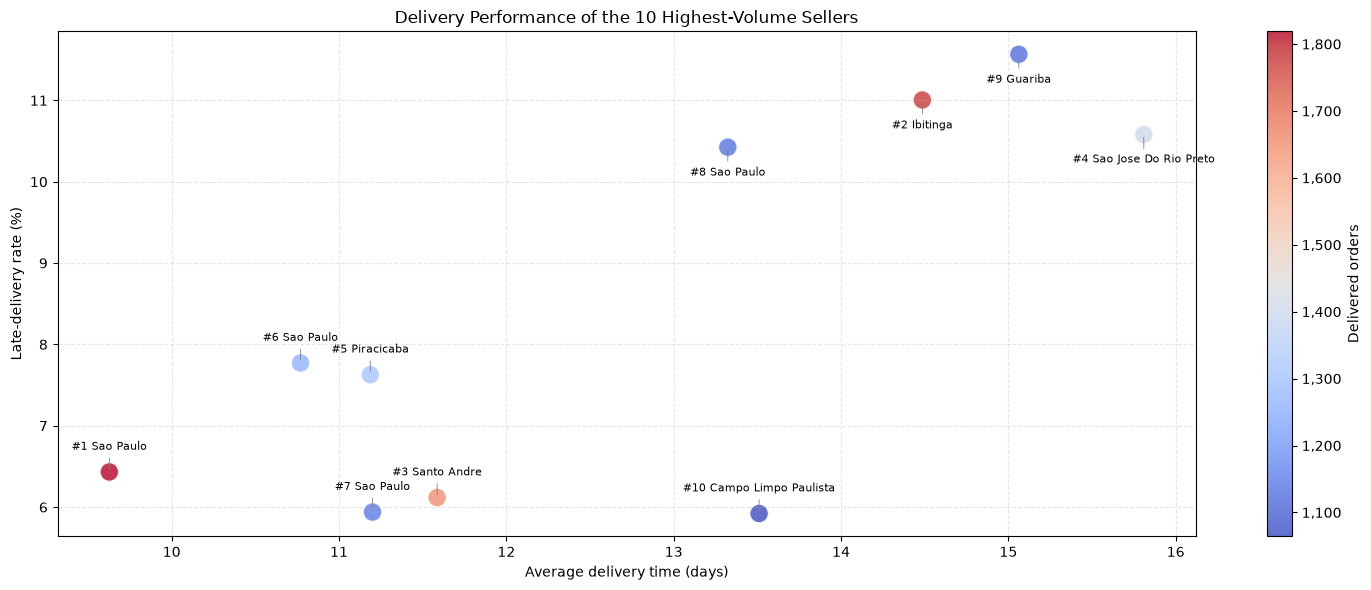

In [305]:
plot_data = seller_delivery_summary.nlargest(10, "delivered_orders").copy()
plot_data["rank"] = range(1, len(plot_data) + 1)

fig, ax = plt.subplots(figsize=(15, 6))

points = ax.scatter(
    plot_data["average_delivery_days"],
    plot_data["late_rate_pct"],
    s=180,
    c=plot_data["delivered_orders"],
    cmap="coolwarm",
    alpha=0.8,
    edgecolors="white",
    linewidth=1,
)

colorbar = fig.colorbar(points, ax=ax)
colorbar.set_label("Delivered orders")
colorbar.ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:,.0f}")
)

y_min, y_max = ax.get_ylim()
y_mid = (y_min + y_max) / 2

for _, row in plot_data.iterrows():
    in_upper_half = row["late_rate_pct"] >= y_mid
    dy = -14 if in_upper_half else 14
    va = "top" if in_upper_half else "bottom"

    ax.annotate(
        f'#{int(row["rank"])} {row["seller_city"].title()}',
        xy=(row["average_delivery_days"], row["late_rate_pct"]),
        xytext=(0, dy),
        textcoords="offset points",
        ha="center",
        va=va,
        fontsize=8,
        arrowprops={"arrowstyle": "-", "color": "gray", "lw": 0.6},
    )

ax.set_xlabel("Average delivery time (days)")
ax.set_ylabel("Late-delivery rate (%)")
ax.set_title("Delivery Performance of the 10 Highest-Volume Sellers")
ax.grid(axis="both", linestyle="--", alpha=0.3)

fig.tight_layout()
plt.show()

<a id="f3"></a>
### F3 · Does the seller's state relate to delivery time or lateness?

In [306]:
seller_state_delivery_summary = (
    seller_orders.groupby("seller_state")
    .agg(
        active_sellers=("seller_id", "nunique"),
        seller_order_pairs=("order_id", "size"),
        average_delivery_days=("delivery_days", "mean"),
        late_orders=("is_late", "sum"),
        late_rate_pct=("is_late", "mean"),
    )
    .assign(
        late_rate_pct=lambda df: df["late_rate_pct"] * 100
    )
    .sort_values("late_rate_pct", ascending=False)
    .round(2)
)

seller_state_delivery_summary

,active_sellers,seller_order_pairs,average_delivery_days,late_orders,late_rate_pct
seller_state,,,,,
AM,1,3,47.84,2,66.67
MA,1,389,17.73,90,23.14
PA,1,8,13.43,1,12.50
RN,5,51,13.12,5,9.80
CE,12,87,17.64,8,9.20
SP,1769,69395,12.32,6016,8.67
RJ,163,4229,12.06,355,8.39
MS,5,49,12.17,4,8.16
ES,22,310,13.08,22,7.10


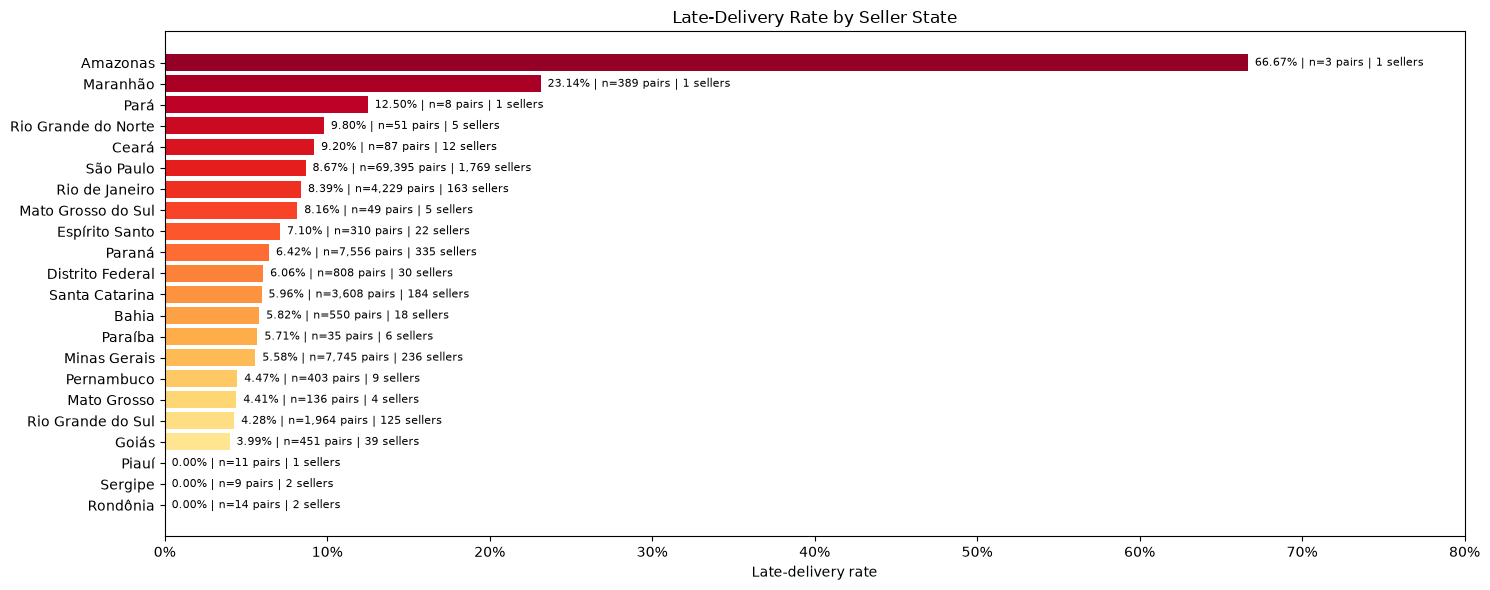

In [307]:
plot_data = seller_state_delivery_summary.reset_index().copy()
plot_data["state_name"] = plot_data["seller_state"].map(state_names)
plot_data = plot_data.sort_values("late_rate_pct")

fig, ax = plt.subplots(figsize=(15, 6))

bars = ax.barh(
    plot_data["state_name"],
    plot_data["late_rate_pct"],
    color=sns.color_palette("YlOrRd", n_colors=len(plot_data)),
)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.annotate(
        f'{row["late_rate_pct"]:.2f}% | n={row["seller_order_pairs"]:,} pairs | '
        f'{row["active_sellers"]:,} sellers',
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
    )

ax.set_xlabel("Late-delivery rate")
ax.set_ylabel("")
ax.set_title("Late-Delivery Rate by Seller State")
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0f}%")
)
ax.set_xlim(0, 80)

plt.tight_layout()
plt.show()

<a id="f4"></a>
### F4 · Do some sellers consistently receive poor reviews?

In [308]:
delivered_order_ids = orders_df.loc[
    orders_df["order_status"].eq("delivered"),
    ["order_id"],
]

review_scores_per_order = (
    order_reviews_df.dropna(subset=["order_id", "review_score"])
    .groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

seller_review_data = (
    order_items_df[["order_id", "seller_id"]]
    .dropna(subset=["seller_id"])
    .drop_duplicates(["order_id", "seller_id"])
    .merge(
        delivered_order_ids,
        on="order_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        review_scores_per_order,
        on="order_id",
        how="inner",
        validate="many_to_one",
    )
)

seller_review_data["low_review"] = seller_review_data["review_score"] <= 2

seller_review_summary = (
    seller_review_data.groupby("seller_id", as_index=False)
    .agg(
        reviewed_orders=("order_id", "nunique"),
        average_review_score=("review_score", "mean"),
        median_review_score=("review_score", "median"),
        low_score_orders=("low_review", "sum"),
        low_score_rate_pct=("low_review", "mean"),
    )
)

seller_review_summary["low_score_rate_pct"] *= 100

min_reviewed_orders = 50

seller_review_ranking = (
    seller_review_summary.loc[
        seller_review_summary["reviewed_orders"] >= min_reviewed_orders
    ]
    .sort_values("low_score_rate_pct", ascending=False)
    .round(2)
)

seller_review_ranking.head(10)

,seller_id,reviewed_orders,average_review_score,median_review_score,low_score_orders,low_score_rate_pct
323,1ca7077d890b907f89be8c954a02686a,107,2.39,1.0,64,59.81
539,2eb70248d66e0e3ef83659f71b244378,184,2.79,3.0,87,47.28
1775,972d0f9cf61b499a4812cf0bfa3ad3c4,79,3.03,3.0,33,41.77
1924,a49928bcdf77c55c6d6e05e09a9b4ca5,96,3.03,3.0,39,40.62
998,54965bbe3e4f07ae045b90b0b8541f52,69,3.14,4.0,28,40.58
2167,bbad7e518d7af88a0897397ffdca1979,67,3.18,4.0,27,40.30
1311,6fd52c528dcb38be2eea044946b811f8,66,3.39,4.0,24,36.36
1334,712e6ed8aa4aa1fa65dab41fed5737e4,76,3.39,4.0,27,35.53
1563,8444e55c1f13cd5c179851e5ca5ebd00,92,3.37,4.0,30,32.61
931,5058e8c1e82653974541e83690655b4a,61,3.25,3.0,19,31.15


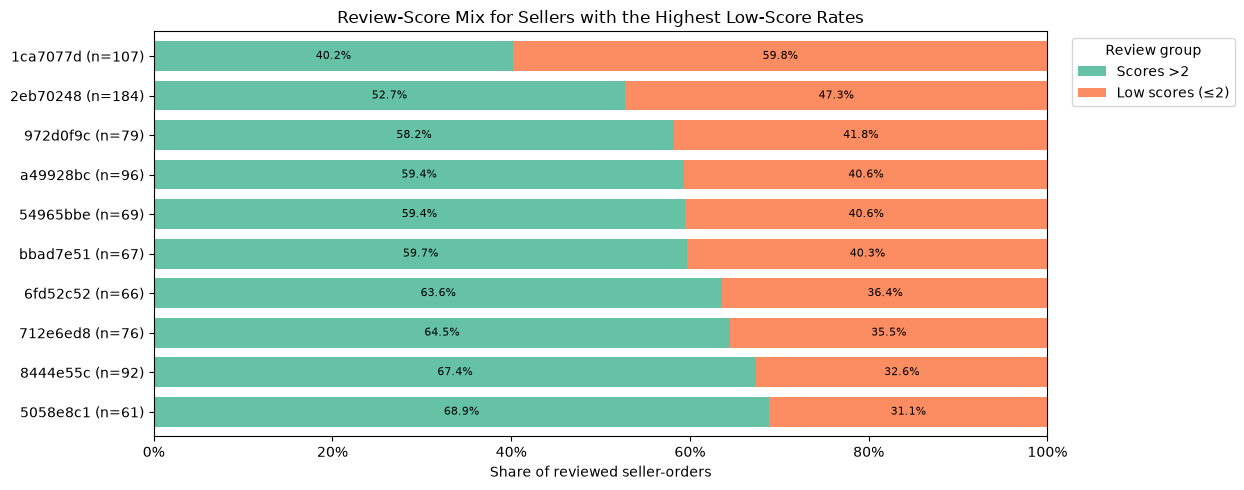

In [309]:
top_sellers = seller_review_ranking.head(10).copy()
top_seller_ids = top_sellers["seller_id"].tolist()
review_groups = ["Scores >2", "Low scores (≤2)"]

top_review_data = seller_review_data.loc[
    seller_review_data["seller_id"].isin(top_seller_ids)
].copy()

top_review_data["review_group"] = top_review_data["low_review"].map(
    {False: "Scores >2", True: "Low scores (≤2)"}
)

review_mix = pd.crosstab(
    top_review_data["seller_id"],
    top_review_data["review_group"],
    normalize="index",
).reindex(index=top_seller_ids, columns=review_groups, fill_value=0) * 100

review_mix.index = [
    f"{seller_id[:8]} (n={review_count:,})"
    for seller_id, review_count in zip(
        top_sellers["seller_id"],
        top_sellers["reviewed_orders"],
    )
]

# Put the highest low-score rate at the top of the horizontal chart.
review_mix = review_mix.iloc[::-1]

fig, ax = plt.subplots(figsize=(15, 5))

review_mix.plot(
    kind="barh",
    stacked=True,
    width=0.75,
    color=sns.color_palette("Set2", n_colors=2),
    ax=ax,
)

for container, group in zip(ax.containers, review_mix.columns):
    ax.bar_label(
        container,
        labels=[f"{value:.1f}%" for value in review_mix[group]],
        label_type="center",
        fontsize=8,
    )

ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0f}%")
)
ax.set_xlabel("Share of reviewed seller-orders")
ax.set_ylabel("")
ax.set_title("Review-Score Mix for Sellers with the Highest Low-Score Rates")
ax.legend(title="Review group", bbox_to_anchor=(1.02, 1), loc="upper left")

fig.tight_layout(rect=[0, 0, 0.84, 1])
plt.show()

<a id="appendix"></a>
---
## Appendix · Supplementary KPIs

*These metrics are quoted in `README.md` and in the PDF report. They reuse the cleaned DataFrames above and follow the same definitions (delivered orders only unless stated).*

In [310]:
# Supplementary KPIs quoted in README.md and Report/Olist_Analysis_Report.pdf
# (uses the DataFrames already loaded and cleaned above)
d_orders = orders_df[orders_df["order_status"].eq("delivered")]
d_items = order_items_df[order_items_df["order_id"].isin(d_orders["order_id"])]

# --- Basket
order_value = d_items.groupby("order_id")["price"].sum()
items_per_order = d_items.groupby("order_id").size()
print("BASKET (delivered orders)")
print(f"  Average order value : R$ {order_value.mean():,.2f}   |  median: R$ {order_value.median():,.2f}")
print(f"  Items per order     : {items_per_order.mean():.2f}   |  single-item orders: {(items_per_order == 1).mean():.1%}")
print(f"  Freight / product   : R$ {d_items['freight_value'].sum():,.2f}  ({d_items['freight_value'].sum() / d_items['price'].sum():.1%} of product value)")

# --- Satisfaction (all review records)
print("\nREVIEWS (all records)")
print(f"  Average score: {order_reviews_df['review_score'].mean():.2f}  |  5-star: {(order_reviews_df['review_score'] == 5).mean():.1%}  |  low (1-2): {(order_reviews_df['review_score'] <= 2).mean():.1%}")

# --- Delivery distribution and promise accuracy
dv = d_orders.dropna(subset=["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]).copy()
dv["days"] = (dv["order_delivered_customer_date"] - dv["order_purchase_timestamp"]).dt.total_seconds() / 86400
dv["promised"] = (dv["order_estimated_delivery_date"] - dv["order_purchase_timestamp"]).dt.total_seconds() / 86400
dv["is_late"] = dv["order_delivered_customer_date"] > dv["order_estimated_delivery_date"]
gap = (dv["order_estimated_delivery_date"] - dv["order_delivered_customer_date"]).dt.total_seconds() / 86400
print("\nDELIVERY")
print(f"  Median {dv['days'].median():.1f} d | mean {dv['days'].mean():.1f} d | P90 {dv['days'].quantile(.9):.1f} d")
print(f"  Average promised window: {dv['promised'].mean():.1f} d")
print(f"  On-time orders arrive {gap[~dv['is_late']].mean():.1f} d early | late orders arrive {-gap[dv['is_late']].mean():.1f} d after the promise")
print(f"  Avg delivery time: on time {dv.loc[~dv['is_late'], 'days'].mean():.1f} d vs late {dv.loc[dv['is_late'], 'days'].mean():.1f} d")

late_by_state = (
    dv.merge(customers_df[["customer_id", "customer_state"]], on="customer_id")
    .groupby("customer_state")
    .agg(delivered_orders=("order_id", "size"), late_rate=("is_late", "mean"))
    .sort_values("late_rate", ascending=False)
)
print("\n  Late rate by customer state (highest 5 / lowest 3):")
print((late_by_state.assign(late_rate=lambda t: (t["late_rate"] * 100).round(1)).iloc[list(range(5)) + [-3, -2, -1]]).to_string())

# --- Concentration
cust = order_items_df.merge(
    orders_df.loc[orders_df["order_status"].eq("delivered"), ["order_id", "customer_id"]], on="order_id"
).merge(customers_df[["customer_id", "customer_unique_id"]], on="customer_id")
cust_sales = cust.groupby("customer_unique_id")["price"].sum().sort_values(ascending=False)
seller_sales = d_items.groupby("seller_id")["price"].sum().sort_values(ascending=False)
print("\nCONCENTRATION")
print(f"  Top 10% of customers = {cust_sales.head(int(len(cust_sales) * .10)).sum() / cust_sales.sum():.1%} of sales | top 1% = {cust_sales.head(int(len(cust_sales) * .01)).sum() / cust_sales.sum():.1%}")
print(f"  Top 20% of sellers  = {seller_sales.head(int(len(seller_sales) * .20)).sum() / seller_sales.sum():.1%} of sales ({len(seller_sales):,} sellers with delivered sales)")
print(f"  Sellers needed for 80% of sales: {(seller_sales.cumsum() / seller_sales.sum() < .8).sum() + 1}")
sp = d_items.merge(sellers_df[["seller_id", "seller_state"]], on="seller_id")
print(f"  São Paulo: {sellers_df['seller_state'].eq('SP').mean():.1%} of registered sellers, {sp.loc[sp['seller_state'].eq('SP'), 'price'].sum() / sp['price'].sum():.1%} of delivered sales")

# --- Payments
cc = order_payments_df[order_payments_df["payment_type"].eq("credit_card") & order_payments_df["payment_installments"].ge(1)]
print("\nCREDIT CARDS")
print(f"  Paid in installments: {(cc['payment_installments'] > 1).mean():.1%} | average installments: {cc['payment_installments'].mean():.1f}")
print(f"  Median payment: R$ {cc.loc[cc['payment_installments'] == 1, 'payment_value'].median():,.2f} (1x) vs R$ {cc.loc[cc['payment_installments'] == 10, 'payment_value'].median():,.2f} (10x)")

BASKET (delivered orders)
  Average order value : R$ 137.04   |  median: R$ 86.57
  Items per order     : 1.14   |  single-item orders: 90.0%
  Freight / product   : R$ 2,198,275.64  (16.6% of product value)

REVIEWS (all records)
  Average score: 4.09  |  5-star: 57.8%  |  low (1-2): 14.7%

DELIVERY
  Median 10.2 d | mean 12.6 d | P90 23.1 d
  Average promised window: 23.7 d
  On-time orders arrive 13.0 d early | late orders arrive 9.6 d after the promise
  Avg delivery time: on time 10.9 d vs late 31.5 d

  Late rate by customer state (highest 5 / lowest 3):
                delivered_orders  late_rate
customer_state                             
AL                           397       23.9
MA                           717       19.7
PI                           476       16.0
CE                          1279       15.3
SE                           335       15.2
AM                           145        4.1
AC                            80        3.8
RO                           243     